# Laboratorio 3 — Análisis de atención en BERT

**Curso:** Procesamiento de Lenguaje Natural
**Corpus:** Franz Kafka, *La metamorfosis* (2 páginas consecutivas seleccionadas al azar)
**Modelo:** `bert-base-multilingual-cased`

En este notebook se analizan oraciones complejas (y algunas simples de control) con un Transformer *encoder-only*. Se inspeccionan las matrices de atención para estudiar cómo distintas capas y cabezas distribuyen la atención entre tokens.

> **Advertencia metodológica.** Los pesos de atención **no** se interpretan aquí como explicaciones causales del comportamiento del modelo; se usan como una ventana parcial a sus representaciones internas y se leen de forma crítica.

### Contenido
0. Configuración
1. Corpus
2. Parte A — Tokenización
3. Parte B — Ejecución del modelo y forma de las matrices
4. Perfil de cabezas y selección de capas/cabezas
5. Parte C — Análisis de atención (top-5)
6. Parte D — Comparación entre oraciones y contextos
7. Subpalabras
8. Preguntas de análisis

## 0. Configuración

In [1]:
# Instalación (descomentar si se ejecuta en Colab o en un entorno nuevo)
# !pip install -q transformers torch pandas matplotlib seaborn

In [2]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModel

torch.manual_seed(0)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

RESULTADOS = Path("resultados")
FIGURAS = RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

MODELO = "bert-base-multilingual-cased"
print("torch", torch.__version__)

c:\users\msi\appdata\local\programs\python\python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.8.0+cpu


## 1. Corpus

Se usó la traducción al español de *La metamorfosis* disponible en Wikisource. El script `preparar_corpus.py` descarga los tres capítulos, limpia el marcado wiki, divide la obra en páginas de **300 palabras** (aproximación a una página de edición de bolsillo) y elige con una semilla fija (`2026`) un índice aleatorio de página; se toman esa página y la siguiente. El resultado está en `corpus/paginas_seleccionadas.txt`.

In [3]:
corpus = Path("corpus/paginas_seleccionadas.txt").read_text(encoding="utf-8")
print(corpus)

Fuente: Franz Kafka, *La metamorfosis*, traducción al español disponible en Wikisource
(https://es.wikisource.org/wiki/La_metamorfosis_(Kafka)).
Paginación: 300 palabras por página -> 69 páginas en total.
Semilla aleatoria: 2026. Páginas seleccionadas: 16 y 17.

--- Página 16 ---
apretaba de nuevo hacia dentro con todo el peso de su cuerpo. El sonido agudo de la cerradura, que se abrió por fin, despertó del todo a Gregorio. Respirando profundamente dijo para sus adentros: «No he necesitado al cerrajero», y apoyó la cabeza sobre el picaporte para abrir la puerta del todo. Como tuvo que abrir la puerta de esta forma, ésta estaba ya bastante abierta y todavía no se le veía. En primer lugar tenía que darse lentamente la vuelta sobre sí mismo, alrededor de la hoja de la puerta, y ello con mucho cuidado si no quería caer torpemente de espaldas justo ante el umbral de la habitación. Todavía estaba absorto en llevar a cabo aquel difícil movimiento y no tenía tiempo de prestar atención a otra c

### Oraciones seleccionadas

De las dos páginas se extraen:

* **Oraciones complejas** (subordinadas, relativas, coordinación larga, dependencias a distancia).
* **Oraciones simples** del mismo fragmento, como control.
* **Pares de contraste** para la Parte D: la palabra *hoja* aparece en el corpus como “hoja de la puerta”; se contrasta con *hoja* en sentido vegetal. Se incluye también el par sugerido con *banco*.

Para cada oración se fijan **2 palabras lingüísticamente relevantes** (sujeto/verbo distante, pronombre relativo con antecedente, núcleo polisémico, etc.).

In [4]:
oraciones = {
    # --- complejas (corpus) ---
    "C1": {
        "texto": "El padre cerró el puño con expresión amenazadora, como si quisiera empujar de nuevo a Gregorio a su habitación, miró inseguro a su alrededor por el cuarto de estar, después se tapó los ojos con las manos y lloró de tal forma que su robusto pecho se estremecía por el llanto.",
        "tipo": "compleja",
        "palabras": ["lloró", "su"],          # verbo lejos de su sujeto 'padre'; posesivo de 'pecho'
        "nota": "Coordinación larga: 'lloró' tiene como sujeto a 'padre', a ~40 tokens de distancia.",
    },
    "C2": {
        "texto": "Gregorio no entró, pues, en la habitación, sino que se apoyó en la parte intermedia de la hoja de la puerta que permanecía cerrada, de modo que sólo podía verse la mitad de su cuerpo y sobre él la cabeza, inclinada a un lado, con la cual miraba hacia los demás.",
        "tipo": "compleja",
        "palabras": ["cual", "él"],           # relativo -> 'cabeza'; pronombre -> 'cuerpo'
        "nota": "'la cual' retoma a 'cabeza'; 'él' retoma a 'cuerpo'.",
    },
    "C3": {
        "texto": "Las piezas de la vajilla del desayuno se extendían en gran cantidad sobre la mesa porque para el padre el desayuno era la comida principal del día, que prolongaba durante horas con la lectura de diversos periódicos.",
        "tipo": "compleja",
        "palabras": ["prolongaba", "desayuno"],  # sujeto implícito 'padre'; 2.ª mención de 'desayuno'
        "nota": "'prolongaba' tiene sujeto tácito (el padre) y objeto 'que' -> 'desayuno'.",
    },
    "C4": {
        "texto": "Justamente en la pared de enfrente había una fotografía de Gregorio, de la época de su servicio militar, que le representaba con uniforme de teniente.",
        "tipo": "compleja",
        "palabras": ["representaba", "le"],    # sujeto 'fotografía' (vía 'que'); clítico 'le' -> Gregorio
        "nota": "'que' retoma a 'fotografía'; 'le' se refiere a Gregorio.",
    },
    # --- simples (corpus) ---
    "S1": {
        "texto": "Entre tanto el día había aclarado.",
        "tipo": "simple",
        "palabras": ["aclarado", "día"],
        "nota": "Oración simple: sujeto 'día', verbo compuesto 'había aclarado'.",
    },
    "S2": {
        "texto": "Todavía caía la lluvia.",
        "tipo": "simple",
        "palabras": ["caía", "lluvia"],
        "nota": "Oración simple con sujeto pospuesto.",
    },
    # --- contraste de contexto ---
    "H1": {
        "texto": "Gregorio se apoyó en la hoja de la puerta que permanecía cerrada.",
        "tipo": "contraste",
        "palabras": ["hoja", "puerta"],
        "nota": "'hoja' = panel de la puerta (sentido del corpus).",
    },
    "H2": {
        "texto": "El viento arrancó una hoja seca del árbol del jardín.",
        "tipo": "contraste",
        "palabras": ["hoja", "árbol"],
        "nota": "'hoja' = parte de una planta.",
    },
    "B1": {
        "texto": "El banco aprobó el préstamo.",
        "tipo": "contraste",
        "palabras": ["banco", "aprobó"],
        "nota": "'banco' = entidad financiera.",
    },
    "B2": {
        "texto": "Me senté en el banco del parque.",
        "tipo": "contraste",
        "palabras": ["banco", "senté"],
        "nota": "'banco' = asiento.",
    },
    "B3": {
        "texto": "El banco me negó el crédito.",
        "tipo": "contraste",
        "palabras": ["banco", "negó"],
        "nota": "'banco' = entidad financiera (referencia del mismo sentido que B1).",
    },
}

# Verificación: las oraciones C* y S* están literalmente en el corpus (salvo C1, que cruza el salto de página)
corpus_plano = re.sub(r"\s+", " ", re.sub(r"--- Página \d+ ---", " ", corpus))
for k, o in oraciones.items():
    if o["tipo"] != "contraste":
        print(k, "en corpus:", o["texto"].rstrip(".") in corpus_plano)

C1 en corpus: True
C2 en corpus: True
C3 en corpus: True
C4 en corpus: True
S1 en corpus: True
S2 en corpus: True


## 2. Parte A — Tokenización

BERT multilingüe usa **WordPiece** con un vocabulario de ~119 000 piezas compartido entre ~100 idiomas. Las piezas que continúan una palabra llevan el prefijo `##`. El tokenizer añade `[CLS]` al inicio y `[SEP]` al final.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODELO)
print("Tamaño del vocabulario:", tokenizer.vocab_size)
print("Tokens especiales:", tokenizer.all_special_tokens)

Tamaño del vocabulario: 119547
Tokens especiales: ['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']


In [6]:
def tokenizar(texto):
    # Devuelve encoding, lista de tokens y, para cada token, el índice de la palabra (pre-tokenizada) a la que pertenece.
    enc = tokenizer(texto, return_tensors="pt")
    tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
    word_ids = enc.word_ids(0)
    return enc, tokens, word_ids

def palabras_de(texto, word_ids):
    # Reconstruye las 'palabras' de la pre-tokenización de BERT (separa puntuación).
    enc = tokenizer(texto, return_offsets_mapping=True)
    palabras = {}
    for wid, (a, b) in zip(enc.word_ids(), enc["offset_mapping"]):
        if wid is not None:
            palabras.setdefault(wid, [a, b])
            palabras[wid][1] = b
    return {wid: texto[a:b] for wid, (a, b) in palabras.items()}

datos = {}
for k, o in oraciones.items():
    enc, tokens, word_ids = tokenizar(o["texto"])
    datos[k] = {"enc": enc, "tokens": tokens, "word_ids": word_ids,
                "palabras": palabras_de(o["texto"], word_ids)}

for k in ["C1", "S1", "B1"]:
    print(f"{k}: {oraciones[k]['texto']}")
    print(datos[k]["tokens"], "\n")

C1: El padre cerró el puño con expresión amenazadora, como si quisiera empujar de nuevo a Gregorio a su habitación, miró inseguro a su alrededor por el cuarto de estar, después se tapó los ojos con las manos y lloró de tal forma que su robusto pecho se estremecía por el llanto.
['[CLS]', 'El', 'padre', 'ce', '##rr', '##ó', 'el', 'pu', '##ño', 'con', 'expresión', 'amenaza', '##dora', ',', 'como', 'si', 'qui', '##sier', '##a', 'em', '##pu', '##jar', 'de', 'nuevo', 'a', 'Gregorio', 'a', 'su', 'habitación', ',', 'mir', '##ó', 'ins', '##egu', '##ro', 'a', 'su', 'alrededor', 'por', 'el', 'cuarto', 'de', 'estar', ',', 'después', 'se', 'tap', '##ó', 'los', 'ojos', 'con', 'las', 'manos', 'y', 'll', '##or', '##ó', 'de', 'tal', 'forma', 'que', 'su', 'ro', '##bust', '##o', 'pe', '##cho', 'se', 'est', '##reme', '##cía', 'por', 'el', 'll', '##anto', '.', '[SEP]'] 

S1: Entre tanto el día había aclarado.
['[CLS]', 'Entre', 'tanto', 'el', 'día', 'había', 'ac', '##lara', '##do', '.', '[SEP]'] 

B1: El 

In [7]:
filas = []
for k, d in datos.items():
    for i, (t, w) in enumerate(zip(d["tokens"], d["word_ids"])):
        filas.append({"oracion": k, "pos": i, "token": t,
                      "id": int(d["enc"]["input_ids"][0, i]),
                      "palabra_idx": w,
                      "palabra": d["palabras"].get(w, "—") if w is not None else "(especial)",
                      "especial": t in tokenizer.all_special_tokens,
                      "subpalabra_continuacion": t.startswith("##")})
tabla_tokens = pd.DataFrame(filas)
tabla_tokens.to_csv(RESULTADOS / "tokens_por_oracion.csv", index=False, encoding="utf-8")
tabla_tokens[tabla_tokens.oracion == "C2"]

,oracion,pos,token,id,palabra_idx,palabra,especial,subpalabra_continuacion
77,C2,0,[CLS],101,NaN,(especial),True,False
78,C2,1,Gregorio,36167,0.0,Gregorio,False,False
79,C2,2,no,10192,1.0,no,False,False
80,C2,3,entró,49750,2.0,entró,False,False
81,C2,4,",",117,3.0,",",False,False
...,...,...,...,...,...,...,...,...
141,C2,64,hacia,15483,54.0,hacia,False,False
142,C2,65,los,10182,55.0,los,False,False
143,C2,66,demás,34002,56.0,demás,False,False
144,C2,67,.,119,57.0,.,False,False


### Tokens especiales y palabras divididas en subpalabras

In [8]:
print("Tokens especiales por oración (posición):")
for k, d in datos.items():
    esp = [(i, t) for i, t in enumerate(d["tokens"]) if t in tokenizer.all_special_tokens]
    print(f"  {k}: {esp}")

filas = []
for k, d in datos.items():
    piezas_por_palabra = {}
    for t, w in zip(d["tokens"], d["word_ids"]):
        if w is not None:
            piezas_por_palabra.setdefault(w, []).append(t)
    for w, piezas in piezas_por_palabra.items():
        if len(piezas) > 1:
            filas.append({"oracion": k, "palabra": d["palabras"][w], "n_piezas": len(piezas), "piezas": " ".join(piezas)})
subpalabras = pd.DataFrame(filas).drop_duplicates(subset=["palabra", "piezas"])
subpalabras.to_csv(RESULTADOS / "palabras_divididas.csv", index=False, encoding="utf-8")
subpalabras

Tokens especiales por oración (posición):
  C1: [(0, '[CLS]'), (76, '[SEP]')]
  C2: [(0, '[CLS]'), (68, '[SEP]')]
  C3: [(0, '[CLS]'), (49, '[SEP]')]
  C4: [(0, '[CLS]'), (34, '[SEP]')]
  S1: [(0, '[CLS]'), (10, '[SEP]')]
  S2: [(0, '[CLS]'), (9, '[SEP]')]
  H1: [(0, '[CLS]'), (20, '[SEP]')]
  H2: [(0, '[CLS]'), (15, '[SEP]')]
  B1: [(0, '[CLS]'), (10, '[SEP]')]
  B2: [(0, '[CLS]'), (10, '[SEP]')]
  B3: [(0, '[CLS]'), (10, '[SEP]')]


,oracion,palabra,n_piezas,piezas
0,C1,cerró,3,ce ##rr ##ó
1,C1,puño,2,pu ##ño
2,C1,amenazadora,2,amenaza ##dora
3,C1,quisiera,3,qui ##sier ##a
4,C1,empujar,3,em ##pu ##jar
5,C1,miró,2,mir ##ó
6,C1,inseguro,3,ins ##egu ##ro
7,C1,tapó,2,tap ##ó
8,C1,lloró,3,ll ##or ##ó
9,C1,robusto,3,ro ##bust ##o


In [9]:
resumen = []
for k, o in oraciones.items():
    d = datos[k]
    palabras_ling = re.findall(r"\w+", o["texto"])          # palabras lingüísticas (sin puntuación)
    n_pre = len(d["palabras"])                               # unidades de la pre-tokenización (incluye puntuación)
    n_tok = len(d["tokens"])
    n_div = sum(1 for w in set(x for x in d["word_ids"] if x is not None)
                if d["word_ids"].count(w) > 1)
    resumen.append({"oracion": k, "tipo": o["tipo"], "palabras_linguisticas": len(palabras_ling),
                    "unidades_pretok (con puntuación)": n_pre, "tokens_modelo (con especiales)": n_tok,
                    "palabras_divididas": n_div, "tokens/palabra": round((n_tok - 2) / len(palabras_ling), 2)})
resumen_tok = pd.DataFrame(resumen)
resumen_tok.to_csv(RESULTADOS / "resumen_tokenizacion.csv", index=False, encoding="utf-8")
resumen_tok

,oracion,tipo,palabras_linguisticas,unidades_pretok (con puntuación),tokens_modelo (con especiales),palabras_divididas,tokens/palabra
0,C1,compleja,51,55,77,13,1.47
1,C2,compleja,51,58,69,6,1.31
2,C3,compleja,37,39,50,5,1.30
3,C4,compleja,25,28,35,4,1.32
4,S1,simple,6,7,11,1,1.50
5,S2,simple,4,5,10,3,2.00
6,H1,contraste,12,13,21,4,1.58
7,H2,contraste,10,11,16,2,1.40
8,B1,contraste,5,6,11,2,1.80
9,B2,contraste,7,8,11,1,1.29


**Observaciones (Parte A).**

* `[CLS]` (posición 0) y `[SEP]` (última posición) aparecen en todas las oraciones; no corresponden a ninguna palabra.
* La puntuación (comas, punto) se separa como tokens propios: el número de tokens del modelo es mayor que el de palabras lingüísticas aunque ninguna palabra se divida.
* Las palabras frecuentes (*el*, *padre*, *puerta*, *banco*) son un solo token. Las palabras menos frecuentes o con morfología verbal rica se fragmentan (ver tabla `palabras_divididas`): la segmentación no sigue los morfemas del español (lexema + desinencia) sino la frecuencia de las piezas en el corpus multilingüe de entrenamiento.
* Por eso la unidad de análisis del modelo (token) no coincide con la unidad lingüística (palabra): una palabra puede ser 1, 2, 3 o más tokens.

## 3. Parte B — Ejecución del modelo

Se carga el modelo con `output_attentions=True`. Se fuerza la implementación *eager* de la atención para que devuelva explícitamente las matrices.

In [10]:
modelo = AutoModel.from_pretrained(MODELO, output_attentions=True, output_hidden_states=True,
                                   attn_implementation="eager")
modelo.eval()
cfg = modelo.config
print(f"Capas: {cfg.num_hidden_layers} | Cabezas por capa: {cfg.num_attention_heads} | Dimensión oculta: {cfg.hidden_size}")

Capas: 12 | Cabezas por capa: 12 | Dimensión oculta: 768


In [11]:
for k, d in datos.items():
    with torch.no_grad():
        outputs = modelo(**d["enc"])
    d["att"] = torch.stack(outputs.attentions).squeeze(1).numpy()   # (capas, cabezas, n, n)
    d["hid"] = torch.stack(outputs.hidden_states).squeeze(1).numpy() # (capas+1, n, 768)
    d["outputs_attentions"] = outputs.attentions

d = datos["C1"]
attentions = d["outputs_attentions"]
print("type(outputs.attentions):", type(attentions), "| len =", len(attentions), "(una por capa)")
print("Forma de cada matriz de atención:", tuple(attentions[0].shape),
      "-> (batch_size, número_de_cabezas, número_de_tokens, número_de_tokens)")
print("Forma apilada (capas, cabezas, n, n):", d["att"].shape)

type(outputs.attentions): <class 'tuple'> | len = 12 (una por capa)
Forma de cada matriz de atención: (1, 12, 77, 77) -> (batch_size, número_de_cabezas, número_de_tokens, número_de_tokens)
Forma apilada (capas, cabezas, n, n): (12, 12, 77, 77)


In [12]:
formas = pd.DataFrame([{"oracion": k, "n_tokens": len(d["tokens"]),
                        "forma_por_capa": str(tuple(d["outputs_attentions"][0].shape)),
                        "n_capas": len(d["outputs_attentions"]),
                        "suma_filas_min": float(d["att"].sum(-1).min()),
                        "suma_filas_max": float(d["att"].sum(-1).max())}
                       for k, d in datos.items()])
formas.to_csv(RESULTADOS / "formas_matrices.csv", index=False)
formas

,oracion,n_tokens,forma_por_capa,n_capas,suma_filas_min,suma_filas_max
0,C1,77,"(1, 12, 77, 77)",12,1.0,1.0
1,C2,69,"(1, 12, 69, 69)",12,1.0,1.0
2,C3,50,"(1, 12, 50, 50)",12,1.0,1.0
3,C4,35,"(1, 12, 35, 35)",12,1.0,1.0
4,S1,11,"(1, 12, 11, 11)",12,1.0,1.0
5,S2,10,"(1, 12, 10, 10)",12,1.0,1.0
6,H1,21,"(1, 12, 21, 21)",12,1.0,1.0
7,H2,16,"(1, 12, 16, 16)",12,1.0,1.0
8,B1,11,"(1, 12, 11, 11)",12,1.0,1.0
9,B2,11,"(1, 12, 11, 11)",12,1.0,1.0


Cada fila de cada matriz suma 1 (es una distribución *softmax* sobre los tokens a los que se atiende). La fila *i* indica cuánto atiende el token *i* (query) a cada token *j* (key).

### Inspección de una matriz: oración S1, capa 1 y capa 12, cabeza 1

In [13]:
def matriz(k, capa, cabeza):
    # capa y cabeza en numeración 1..12
    d = datos[k]
    return pd.DataFrame(d["att"][capa - 1, cabeza - 1], index=d["tokens"], columns=d["tokens"]).round(3)

display(matriz("S1", 1, 1))
display(matriz("S1", 12, 1))

,[CLS],Entre,tanto,el,día,había,ac,##lara,##do,.,[SEP]
[CLS],0.098,0.006,0.002,0.012,0.007,0.022,0.008,0.003,0.002,0.029,0.811
Entre,0.110,0.122,0.124,0.104,0.052,0.119,0.056,0.031,0.051,0.066,0.165
tanto,0.396,0.041,0.117,0.017,0.060,0.098,0.004,0.023,0.040,0.107,0.096
el,0.048,0.074,0.021,0.477,0.077,0.080,0.027,0.004,0.059,0.063,0.069
día,0.361,0.067,0.022,0.010,0.225,0.031,0.013,0.027,0.045,0.044,0.155
había,0.216,0.098,0.040,0.036,0.107,0.093,0.013,0.050,0.082,0.082,0.185
ac,0.059,0.072,0.075,0.097,0.142,0.146,0.107,0.035,0.040,0.094,0.134
##lara,0.335,0.053,0.011,0.018,0.107,0.089,0.014,0.131,0.062,0.097,0.083
##do,0.112,0.091,0.044,0.038,0.235,0.157,0.009,0.014,0.071,0.096,0.133
.,0.254,0.031,0.034,0.016,0.056,0.066,0.016,0.037,0.018,0.034,0.438


,[CLS],Entre,tanto,el,día,había,ac,##lara,##do,.,[SEP]
[CLS],0.187,0.013,0.011,0.055,0.096,0.051,0.027,0.019,0.050,0.246,0.244
Entre,0.228,0.073,0.024,0.156,0.032,0.043,0.007,0.013,0.014,0.273,0.137
tanto,0.283,0.047,0.118,0.127,0.060,0.037,0.008,0.023,0.041,0.116,0.140
el,0.110,0.011,0.004,0.141,0.091,0.048,0.016,0.041,0.014,0.392,0.132
día,0.149,0.007,0.012,0.083,0.209,0.023,0.030,0.112,0.079,0.154,0.142
había,0.219,0.005,0.004,0.070,0.106,0.042,0.022,0.023,0.023,0.318,0.168
ac,0.214,0.005,0.002,0.071,0.055,0.058,0.068,0.101,0.028,0.263,0.134
##lara,0.204,0.008,0.006,0.130,0.048,0.040,0.045,0.227,0.070,0.107,0.116
##do,0.287,0.002,0.005,0.025,0.063,0.045,0.018,0.031,0.075,0.310,0.139
.,0.239,0.002,0.002,0.023,0.069,0.020,0.013,0.008,0.018,0.398,0.209


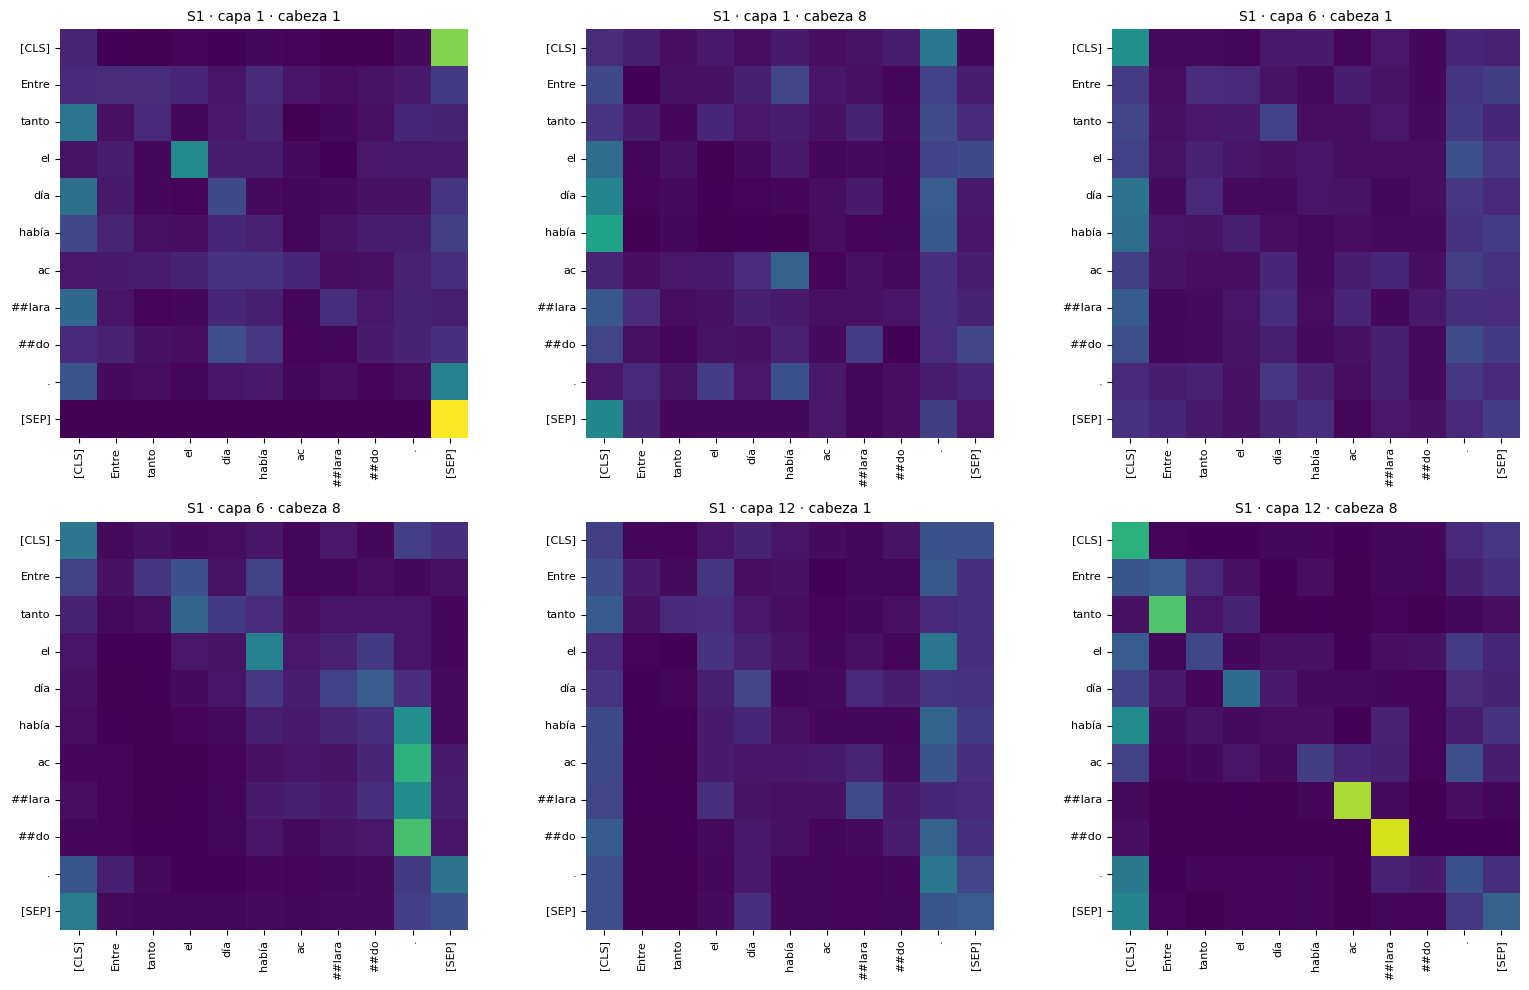

In [14]:
def heatmap(k, capa, cabeza, ax=None):
    d = datos[k]
    ax = ax or plt.gca()
    sns.heatmap(d["att"][capa - 1, cabeza - 1], xticklabels=d["tokens"], yticklabels=d["tokens"],
                cmap="viridis", vmin=0, vmax=1, ax=ax, cbar=False, square=True)
    ax.set_title(f"{k} · capa {capa} · cabeza {cabeza}", fontsize=10)
    ax.tick_params(labelsize=8)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (capa, cabeza) in zip(axes.flat, [(1, 1), (1, 8), (6, 1), (6, 8), (12, 1), (12, 8)]):
    heatmap("S1", capa, cabeza, ax)
plt.tight_layout(); plt.savefig(FIGURAS / "heatmaps_S1.png", dpi=120); plt.show()

## 4. Perfil de cabezas y selección de capas/cabezas

Con 12 × 12 = 144 cabezas, elegir cabezas al azar suele devolver cabezas que sólo miran a `[SEP]`. Para escoger de forma justificada se calcula, promediando sobre todas las oraciones y sobre todos los tokens no especiales:

* `% a [CLS]` y `% a [SEP]`: masa de atención que va a los tokens especiales.
* `% a sí mismo`, `% al anterior`, `% al siguiente`: patrones posicionales.
* `entropía`: qué tan dispersa es la distribución (baja = enfocada).

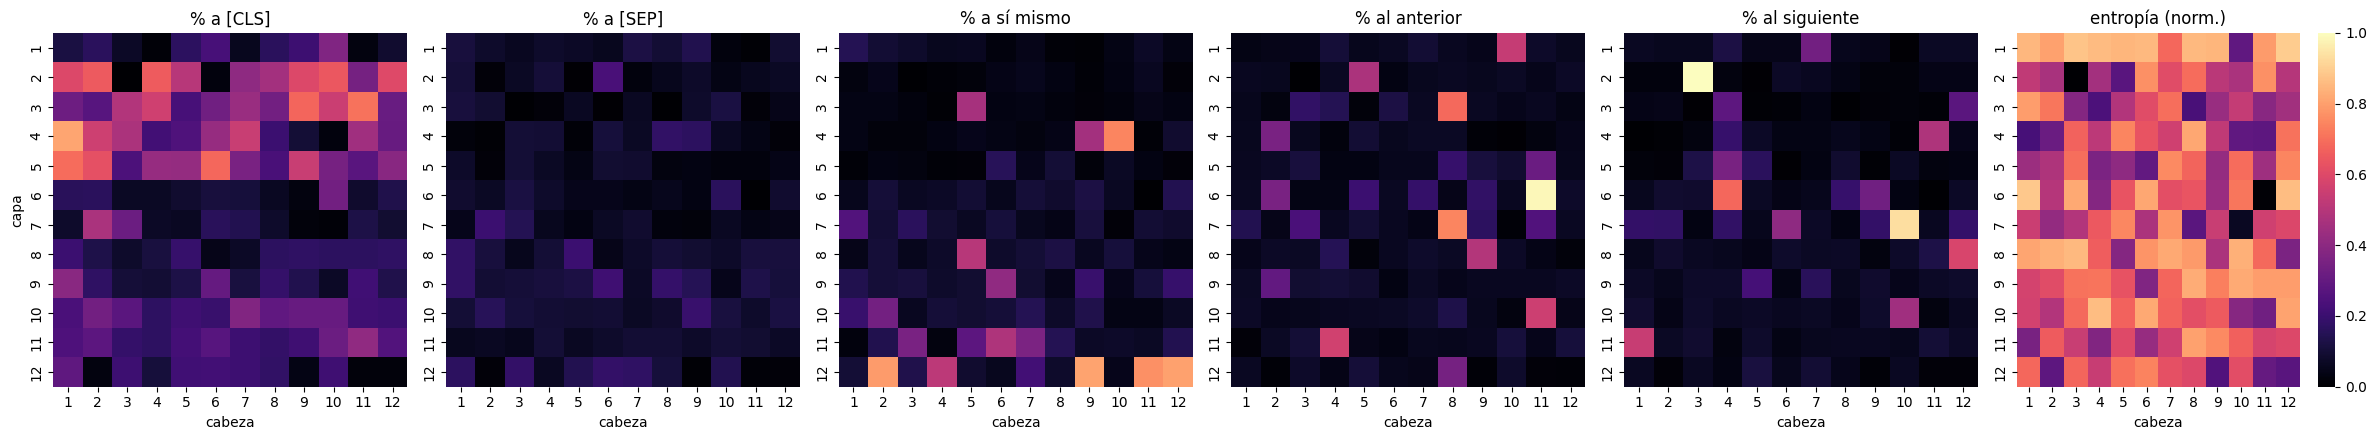

,% a [CLS],% a [SEP],% a sí mismo,% al anterior,% al siguiente,entropía (norm.)
capa,,,,,,
1,0.139,0.079,0.057,0.102,0.081,0.787
2,0.455,0.071,0.030,0.088,0.116,0.503
3,0.434,0.053,0.066,0.126,0.064,0.496
4,0.363,0.073,0.130,0.074,0.084,0.524
5,0.435,0.052,0.046,0.097,0.079,0.534
6,0.118,0.069,0.080,0.191,0.141,0.608
7,0.136,0.070,0.098,0.160,0.208,0.511
8,0.140,0.105,0.111,0.100,0.111,0.688
9,0.171,0.127,0.135,0.087,0.087,0.686


In [15]:
def perfil_cabezas():
    regs = []
    for k, d in datos.items():
        A = d["att"]                       # (L, H, n, n)
        n = A.shape[-1]
        q = np.arange(1, n - 1)            # queries no especiales
        cls = A[:, :, q, 0].mean(-1)
        sep = A[:, :, q, n - 1].mean(-1)
        self_ = A[:, :, q, q].mean(-1)
        prev = A[:, :, q, q - 1].mean(-1)
        nxt = A[:, :, q, q + 1].mean(-1)
        ent = (-(A[:, :, q, :] * np.log(A[:, :, q, :] + 1e-12)).sum(-1)).mean(-1) / np.log(n)
        regs.append(np.stack([cls, sep, self_, prev, nxt, ent], -1))
    return np.mean(regs, 0)                # (L, H, 6)

P = perfil_cabezas()
metricas = ["% a [CLS]", "% a [SEP]", "% a sí mismo", "% al anterior", "% al siguiente", "entropía (norm.)"]
fig, axes = plt.subplots(1, 6, figsize=(24, 4.5))
for i, (ax, m) in enumerate(zip(axes, metricas)):
    sns.heatmap(P[:, :, i], ax=ax, cmap="magma", vmin=0, vmax=1, cbar=i == 5,
                xticklabels=range(1, 13), yticklabels=range(1, 13))
    ax.set_title(m); ax.set_xlabel("cabeza"); ax.set_ylabel("capa" if i == 0 else "")
plt.tight_layout(); plt.savefig(FIGURAS / "perfil_cabezas.png", dpi=120); plt.show()

perfil = pd.DataFrame([{"capa": l + 1, "cabeza": h + 1, **{m: round(float(P[l, h, i]), 3) for i, m in enumerate(metricas)}}
                       for l in range(12) for h in range(12)])
perfil.to_csv(RESULTADOS / "perfil_cabezas.csv", index=False, encoding="utf-8")
perfil.groupby("capa")[metricas].mean().round(3)

**Criterio de selección.** Se analizan **3 capas**: una temprana (**3**), una intermedia (**7**) y una tardía (**11**) — se pide al menos 2. En cada capa se eligen **2 cabezas** con comportamientos contrastantes:

* **Cabeza posicional**: la de mayor atención promedio al token vecino (anterior o siguiente).
* **Cabeza contextual**: entre las cabezas que dedican menos del 50 % de su atención a `[CLS]`/`[SEP]` y menos del 50 % a vecinos, la de mayor entropía (atención distribuida sobre la oración).

In [16]:
CAPAS = [3, 7, 11]
seleccion = {}
for c in CAPAS:
    p = perfil[perfil.capa == c].copy()
    p["vecino"] = p[["% al anterior", "% al siguiente"]].max(axis=1)
    p["especiales"] = p["% a [CLS]"] + p["% a [SEP]"]
    posicional = int(p.sort_values("vecino", ascending=False).iloc[0].cabeza)
    cand = p[(p.especiales < 0.5) & (p.vecino < 0.5) & (p.cabeza != posicional)]
    if cand.empty:
        cand = p[p.cabeza != posicional].sort_values("especiales").head(4)
    contextual = int(cand.sort_values("entropía (norm.)", ascending=False).iloc[0].cabeza)
    seleccion[c] = {"posicional": posicional, "contextual": contextual}

sel_df = pd.DataFrame([{"capa": c, "rol": rol, "cabeza": h,
                        **perfil[(perfil.capa == c) & (perfil.cabeza == h)][metricas].iloc[0].to_dict()}
                       for c, s in seleccion.items() for rol, h in s.items()])
sel_df.to_csv(RESULTADOS / "cabezas_seleccionadas.csv", index=False, encoding="utf-8")
sel_df

,capa,rol,cabeza,% a [CLS],% a [SEP],% a sí mismo,% al anterior,% al siguiente,entropía (norm.)
0,3,posicional,8,0.334,0.003,0.026,0.686,0.004,0.231
1,3,contextual,1,0.323,0.113,0.037,0.051,0.040,0.793
2,7,posicional,10,0.014,0.066,0.018,0.012,0.931,0.063
3,7,contextual,7,0.144,0.087,0.056,0.040,0.074,0.777
4,11,posicional,4,0.170,0.100,0.030,0.564,0.029,0.374
5,11,contextual,8,0.182,0.096,0.148,0.052,0.061,0.802


## 5. Parte C — Análisis de atención

Para cada oración, cada palabra seleccionada, cada capa y cada cabeza elegida se muestran los **5 tokens con mayor peso de atención** (fila del token seleccionado en la matriz). Si la palabra seleccionada se divide en subpalabras se usa su **primera pieza** como query (en la sección 7 se analiza el efecto de esa decisión).

Se reportan dos versiones:
* **Top-5 bruto**: incluye `[CLS]`, `[SEP]` y puntuación, tal como lo produce el modelo.
* **Top-5 sin especiales**: excluye `[CLS]`/`[SEP]` y el propio token, para ver a qué *palabras* mira.

In [17]:
def posiciones_palabra(k, palabra, ocurrencia=0):
    # Posiciones de los tokens que forman la palabra (ocurrencia n-ésima)
    d = datos[k]
    wids = [w for w, p in d["palabras"].items() if p == palabra]
    w = wids[ocurrencia]
    return [i for i, x in enumerate(d["word_ids"]) if x == w]

def top_k(k, capa, cabeza, pos, n=5, excluir_especiales=False):
    d = datos[k]
    fila = d["att"][capa - 1, cabeza - 1, pos].copy()
    orden = np.argsort(-fila)
    if excluir_especiales:
        ultimo = len(d["tokens"]) - 1
        orden = [j for j in orden if j not in (0, ultimo, pos)]
    return [(d["tokens"][j], int(j), float(fila[j])) for j in orden[:n]]

def fmt(lista):
    return " | ".join(f"{t}@{j} ({w:.3f})" for t, j, w in lista)

filas = []
for k, o in oraciones.items():
    for palabra in o["palabras"]:
        ocurr = 1 if (k == "C3" and palabra == "desayuno") else 0   # 2.ª mención de 'desayuno'
        pos = posiciones_palabra(k, palabra, ocurr)
        q = pos[0]
        for capa in CAPAS:
            for rol, cabeza in seleccion[capa].items():
                bruto = top_k(k, capa, cabeza, q)
                limpio = top_k(k, capa, cabeza, q, excluir_especiales=True)
                filas.append({"oracion": k, "tipo": o["tipo"], "palabra": palabra,
                              "token_query": f"{datos[k]['tokens'][q]}@{q}",
                              "capa": capa, "cabeza": cabeza, "rol_cabeza": rol,
                              "top5_bruto": fmt(bruto), "top5_sin_especiales": fmt(limpio),
                              "masa_especiales": round(float(datos[k]['att'][capa-1, cabeza-1, q, [0, -1]].sum()), 3)})
top5 = pd.DataFrame(filas)
top5.to_csv(RESULTADOS / "top5_atencion.csv", index=False, encoding="utf-8")
print("Filas en la tabla de resultados:", len(top5))

Filas en la tabla de resultados: 132


La notación `token@pos (peso)` indica el token, su posición en la oración y el peso de atención que recibe desde la palabra seleccionada.

In [18]:
def mostrar(k):
    print(f"[{k}] {oraciones[k]['texto']}\n      {oraciones[k]['nota']}")
    display(top5[top5.oracion == k].drop(columns=["oracion", "tipo"]).reset_index(drop=True))

for k in ["C1", "C2", "C3", "C4"]:
    mostrar(k)

[C1] El padre cerró el puño con expresión amenazadora, como si quisiera empujar de nuevo a Gregorio a su habitación, miró inseguro a su alrededor por el cuarto de estar, después se tapó los ojos con las manos y lloró de tal forma que su robusto pecho se estremecía por el llanto.
      Coordinación larga: 'lloró' tiene como sujeto a 'padre', a ~40 tokens de distancia.


,palabra,token_query,capa,cabeza,rol_cabeza,top5_bruto,top5_sin_especiales,masa_especiales
0,lloró,ll@54,3,8,posicional,[CLS]@0 (0.751) | y@53 (0.239) | ll@54 (0.004) | manos@52 (0.003) | ##ó@56 (0.000),y@53 (0.239) | manos@52 (0.003) | ##ó@56 (0.000) | padre@2 (0.000) | ##or@55 (0.000),0.751
1,lloró,ll@54,3,1,contextual,"[CLS]@0 (0.397) | ,@43 (0.095) | ,@29 (0.045) | [SEP]@76 (0.025) | ,@13 (0.021)",",@43 (0.095) | ,@29 (0.045) | ,@13 (0.021) | .@75 (0.019) | ojos@49 (0.015)",0.422
2,lloró,ll@54,7,10,posicional,##or@55 (0.999) | ##ó@56 (0.001) | ll@54 (0.000) | ##rr@4 (0.000) | forma@59 (0.000),##or@55 (0.999) | ##ó@56 (0.001) | ##rr@4 (0.000) | forma@59 (0.000) | tal@58 (0.000),0.000
3,lloró,ll@54,7,7,contextual,que@60 (0.233) | forma@59 (0.225) | [CLS]@0 (0.104) | tal@58 (0.052) | su@61 (0.049),que@60 (0.233) | forma@59 (0.225) | tal@58 (0.052) | su@61 (0.049) | ##or@55 (0.045),0.109
4,lloró,ll@54,11,4,posicional,[CLS]@0 (0.686) | [SEP]@76 (0.167) | y@53 (0.037) | ##ó@56 (0.022) | ##ó@47 (0.011),y@53 (0.037) | ##ó@56 (0.022) | ##ó@47 (0.011) | se@67 (0.010) | se@45 (0.010),0.853
5,lloró,ll@54,11,8,contextual,[CLS]@0 (0.180) | ll@73 (0.155) | ll@54 (0.141) | tap@46 (0.074) | [SEP]@76 (0.051),ll@73 (0.155) | tap@46 (0.074) | .@75 (0.034) | est@68 (0.031) | forma@59 (0.025),0.231
6,su,su@27,3,8,posicional,a@26 (0.902) | [CLS]@0 (0.081) | Gregorio@25 (0.008) | su@27 (0.004) | habitación@28 (0.002),a@26 (0.902) | Gregorio@25 (0.008) | habitación@28 (0.002) | expresión@10 (0.001) | después@44 (0.000),0.081
7,su,su@27,3,1,contextual,"[CLS]@0 (0.221) | expresión@10 (0.051) | ,@29 (0.036) | ,@13 (0.035) | ,@43 (0.024)","expresión@10 (0.051) | ,@29 (0.036) | ,@13 (0.035) | ,@43 (0.024) | El@1 (0.024)",0.235
8,su,su@27,7,10,posicional,habitación@28 (1.000) | [CLS]@0 (0.000) | su@27 (0.000) | expresión@10 (0.000) | Gregorio@25 (0.000),habitación@28 (1.000) | expresión@10 (0.000) | Gregorio@25 (0.000) | nuevo@23 (0.000) | cuarto@40 (0.000),0.000
9,su,su@27,7,7,contextual,"[CLS]@0 (0.364) | ,@29 (0.335) | Gregorio@25 (0.040) | habitación@28 (0.035) | ,@43 (0.032)",",@29 (0.335) | Gregorio@25 (0.040) | habitación@28 (0.035) | ,@43 (0.032) | ##ó@31 (0.023)",0.380


[C2] Gregorio no entró, pues, en la habitación, sino que se apoyó en la parte intermedia de la hoja de la puerta que permanecía cerrada, de modo que sólo podía verse la mitad de su cuerpo y sobre él la cabeza, inclinada a un lado, con la cual miraba hacia los demás.
      'la cual' retoma a 'cabeza'; 'él' retoma a 'cuerpo'.


,palabra,token_query,capa,cabeza,rol_cabeza,top5_bruto,top5_sin_especiales,masa_especiales
0,cual,cual@61,3,8,posicional,la@60 (0.732) | [CLS]@0 (0.166) | cual@61 (0.043) | con@59 (0.021) | habitación@9 (0.012),"la@60 (0.732) | con@59 (0.021) | habitación@9 (0.012) | ,@58 (0.006) | sino@11 (0.006)",0.168
1,cual,cual@61,3,1,contextual,"[CLS]@0 (0.425) | ,@58 (0.049) | ,@51 (0.046) | .@67 (0.040) | [SEP]@68 (0.033)",",@58 (0.049) | ,@51 (0.046) | .@67 (0.040) | ,@34 (0.028) | ,@4 (0.022)",0.458
2,cual,cual@61,7,10,posicional,mira@62 (0.986) | ##ba@63 (0.007) | [CLS]@0 (0.005) | con@59 (0.001) | hacia@64 (0.001),mira@62 (0.986) | ##ba@63 (0.007) | con@59 (0.001) | hacia@64 (0.001) | .@67 (0.000),0.005
3,cual,cual@61,7,7,contextual,[CLS]@0 (0.354) | demás@66 (0.127) | hacia@64 (0.126) | mira@62 (0.079) | los@65 (0.065),demás@66 (0.127) | hacia@64 (0.126) | mira@62 (0.079) | los@65 (0.065) | .@67 (0.062),0.403
4,cual,cual@61,11,4,posicional,la@60 (0.922) | [CLS]@0 (0.037) | [SEP]@68 (0.015) | con@59 (0.006) | un@56 (0.005),la@60 (0.922) | con@59 (0.006) | un@56 (0.005) | la@17 (0.003) | los@65 (0.001),0.052
5,cual,cual@61,11,8,contextual,[CLS]@0 (0.387) | [SEP]@68 (0.109) | cabeza@50 (0.068) | cual@61 (0.066) | con@59 (0.024),"cabeza@50 (0.068) | con@59 (0.024) | la@49 (0.024) | ##clin@53 (0.021) | ,@58 (0.021)",0.496
6,él,él@48,3,8,posicional,sobre@47 (0.919) | él@48 (0.039) | [CLS]@0 (0.031) | y@46 (0.004) | apo@14 (0.002),sobre@47 (0.919) | y@46 (0.004) | apo@14 (0.002) | la@49 (0.001) | cuerpo@45 (0.001),0.031
7,él,él@48,3,1,contextual,"[CLS]@0 (0.156) | ,@58 (0.040) | ,@51 (0.040) | [SEP]@68 (0.039) | .@67 (0.037)",",@58 (0.040) | ,@51 (0.040) | .@67 (0.037) | ,@34 (0.033) | cabeza@50 (0.032)",0.195
8,él,él@48,7,10,posicional,"la@49 (0.661) | cabeza@50 (0.194) | [CLS]@0 (0.080) | y@46 (0.026) | ,@51 (0.016)","la@49 (0.661) | cabeza@50 (0.194) | y@46 (0.026) | ,@51 (0.016) | cuerpo@45 (0.013)",0.080
9,él,él@48,7,7,contextual,"[CLS]@0 (0.317) | cabeza@50 (0.128) | ,@51 (0.120) | .@67 (0.046) | ##ada@54 (0.036)","cabeza@50 (0.128) | ,@51 (0.120) | .@67 (0.046) | ##ada@54 (0.036) | in@52 (0.032)",0.347


[C3] Las piezas de la vajilla del desayuno se extendían en gran cantidad sobre la mesa porque para el padre el desayuno era la comida principal del día, que prolongaba durante horas con la lectura de diversos periódicos.
      'prolongaba' tiene sujeto tácito (el padre) y objeto 'que' -> 'desayuno'.


,palabra,token_query,capa,cabeza,rol_cabeza,top5_bruto,top5_sin_especiales,masa_especiales
0,prolongaba,pro@37,3,8,posicional,que@36 (0.492) | [CLS]@0 (0.471) | pro@37 (0.013) | porque@21 (0.008) | ##long@38 (0.004),"que@36 (0.492) | porque@21 (0.008) | ##long@38 (0.004) | ##aba@39 (0.003) | ,@35 (0.003)",0.471
1,prolongaba,pro@37,3,1,contextual,[CLS]@0 (0.270) | periódicos@47 (0.070) | [SEP]@49 (0.042) | .@48 (0.035) | padre@24 (0.033),"periódicos@47 (0.070) | .@48 (0.035) | padre@24 (0.033) | piezas@2 (0.033) | ,@35 (0.033)",0.312
2,prolongaba,pro@37,7,10,posicional,##long@38 (0.999) | pro@37 (0.000) | ##aba@39 (0.000) | durante@40 (0.000) | horas@41 (0.000),##long@38 (0.999) | ##aba@39 (0.000) | durante@40 (0.000) | horas@41 (0.000) | lectura@44 (0.000),0.000
3,prolongaba,pro@37,7,7,contextual,con@42 (0.285) | lectura@44 (0.132) | durante@40 (0.078) | periódicos@47 (0.076) | la@43 (0.065),con@42 (0.285) | lectura@44 (0.132) | durante@40 (0.078) | periódicos@47 (0.076) | la@43 (0.065),0.073
4,prolongaba,pro@37,11,4,posicional,que@36 (0.971) | ##aba@39 (0.017) | pro@37 (0.004) | se@12 (0.003) | ##ían@14 (0.001),"que@36 (0.971) | ##aba@39 (0.017) | se@12 (0.003) | ##ían@14 (0.001) | ,@35 (0.001)",0.001
5,prolongaba,pro@37,11,8,contextual,[CLS]@0 (0.278) | padre@24 (0.081) | .@48 (0.060) | [SEP]@49 (0.057) | día@34 (0.035),"padre@24 (0.081) | .@48 (0.060) | día@34 (0.035) | ,@35 (0.034) | diversos@46 (0.033)",0.334
6,desayuno,desa@26,3,8,posicional,[CLS]@0 (0.725) | el@25 (0.246) | desa@26 (0.008) | padre@24 (0.007) | ##no@28 (0.005),el@25 (0.246) | padre@24 (0.007) | ##no@28 (0.005) | ##yu@27 (0.004) | ##yu@10 (0.002),0.725
7,desayuno,desa@26,3,1,contextual,[CLS]@0 (0.425) | piezas@2 (0.040) | [SEP]@49 (0.040) | periódicos@47 (0.033) | .@48 (0.032),"piezas@2 (0.040) | periódicos@47 (0.033) | .@48 (0.032) | ,@35 (0.029) | mesa@20 (0.027)",0.465
8,desayuno,desa@26,7,10,posicional,##yu@27 (0.994) | ##yu@10 (0.006) | desa@26 (0.000) | ##no@28 (0.000) | ##jil@6 (0.000),##yu@27 (0.994) | ##yu@10 (0.006) | ##no@28 (0.000) | ##jil@6 (0.000) | padre@24 (0.000),0.000
9,desayuno,desa@26,7,7,contextual,comida@31 (0.163) | [CLS]@0 (0.135) | principal@32 (0.111) | la@30 (0.106) | era@29 (0.097),"comida@31 (0.163) | principal@32 (0.111) | la@30 (0.106) | era@29 (0.097) | ,@35 (0.069)",0.162


[C4] Justamente en la pared de enfrente había una fotografía de Gregorio, de la época de su servicio militar, que le representaba con uniforme de teniente.
      'que' retoma a 'fotografía'; 'le' se refiere a Gregorio.


,palabra,token_query,capa,cabeza,rol_cabeza,top5_bruto,top5_sin_especiales,masa_especiales
0,representaba,representa@27,3,8,posicional,le@26 (0.592) | [CLS]@0 (0.380) | representa@27 (0.013) | que@25 (0.006) | con@29 (0.005),"le@26 (0.592) | que@25 (0.006) | con@29 (0.005) | ,@24 (0.001) | ##ba@28 (0.001)",0.381
1,representaba,representa@27,3,1,contextual,[CLS]@0 (0.171) | había@11 (0.064) | [SEP]@34 (0.056) | .@33 (0.052) | ##ba@28 (0.047),"había@11 (0.064) | .@33 (0.052) | ##ba@28 (0.047) | ##fre@9 (0.043) | ,@24 (0.036)",0.227
2,representaba,representa@27,7,10,posicional,##ba@28 (0.993) | representa@27 (0.003) | con@29 (0.002) | le@26 (0.001) | había@11 (0.000),##ba@28 (0.993) | con@29 (0.002) | le@26 (0.001) | había@11 (0.000) | uniforme@30 (0.000),0.000
3,representaba,representa@27,7,7,contextual,[SEP]@34 (0.249) | .@33 (0.232) | con@29 (0.141) | uniforme@30 (0.103) | de@31 (0.068),.@33 (0.232) | con@29 (0.141) | uniforme@30 (0.103) | de@31 (0.068) | ##ba@28 (0.032),0.291
4,representaba,representa@27,11,4,posicional,le@26 (0.306) | la@18 (0.244) | que@25 (0.083) | [SEP]@34 (0.078) | con@29 (0.064),le@26 (0.306) | la@18 (0.244) | que@25 (0.083) | con@29 (0.064) | de@17 (0.060),0.094
5,representaba,representa@27,11,8,contextual,.@33 (0.113) | Gregorio@15 (0.101) | representa@27 (0.085) | de@14 (0.074) | le@26 (0.064),.@33 (0.113) | Gregorio@15 (0.101) | de@14 (0.074) | le@26 (0.064) | ##nte@10 (0.045),0.118
6,le,le@26,3,8,posicional,"que@25 (0.653) | [CLS]@0 (0.323) | le@26 (0.012) | representa@27 (0.005) | ,@24 (0.003)","que@25 (0.653) | representa@27 (0.005) | ,@24 (0.003) | ##ba@28 (0.001) | ##fre@9 (0.001)",0.324
7,le,le@26,3,1,contextual,"[CLS]@0 (0.548) | representa@27 (0.040) | ##ba@28 (0.037) | ,@24 (0.037) | .@33 (0.034)","representa@27 (0.040) | ##ba@28 (0.037) | ,@24 (0.037) | .@33 (0.034) | ,@16 (0.028)",0.573
8,le,le@26,7,10,posicional,representa@27 (0.934) | con@29 (0.044) | uniforme@30 (0.011) | [CLS]@0 (0.003) | ##ba@28 (0.003),representa@27 (0.934) | con@29 (0.044) | uniforme@30 (0.011) | ##ba@28 (0.003) | había@11 (0.001),0.003
9,le,le@26,7,7,contextual,con@29 (0.197) | .@33 (0.163) | uniforme@30 (0.143) | [SEP]@34 (0.140) | de@31 (0.137),con@29 (0.197) | .@33 (0.163) | uniforme@30 (0.143) | de@31 (0.137) | teniente@32 (0.058),0.201


In [19]:
for k in ["S1", "S2"]:
    mostrar(k)

[S1] Entre tanto el día había aclarado.
      Oración simple: sujeto 'día', verbo compuesto 'había aclarado'.


,palabra,token_query,capa,cabeza,rol_cabeza,top5_bruto,top5_sin_especiales,masa_especiales
0,aclarado,ac@6,3,8,posicional,[CLS]@0 (0.653) | había@5 (0.267) | ac@6 (0.027) | ##do@8 (0.023) | día@4 (0.011),había@5 (0.267) | ##do@8 (0.023) | día@4 (0.011) | ##lara@7 (0.011) | el@3 (0.002),0.654
1,aclarado,ac@6,3,1,contextual,[CLS]@0 (0.324) | [SEP]@10 (0.188) | .@9 (0.162) | ##lara@7 (0.081) | Entre@1 (0.062),.@9 (0.162) | ##lara@7 (0.081) | Entre@1 (0.062) | había@5 (0.057) | día@4 (0.053),0.512
2,aclarado,ac@6,7,10,posicional,##lara@7 (1.000) | día@4 (0.000) | ac@6 (0.000) | .@9 (0.000) | [CLS]@0 (0.000),##lara@7 (1.000) | día@4 (0.000) | .@9 (0.000) | ##do@8 (0.000) | había@5 (0.000),0.000
3,aclarado,ac@6,7,7,contextual,.@9 (0.322) | [CLS]@0 (0.133) | Entre@1 (0.119) | [SEP]@10 (0.108) | ac@6 (0.091),.@9 (0.322) | Entre@1 (0.119) | había@5 (0.057) | ##lara@7 (0.054) | día@4 (0.036),0.241
4,aclarado,ac@6,11,4,posicional,había@5 (0.641) | ##do@8 (0.092) | día@4 (0.068) | ac@6 (0.049) | [CLS]@0 (0.044),había@5 (0.641) | ##do@8 (0.092) | día@4 (0.068) | el@3 (0.033) | ##lara@7 (0.022),0.076
5,aclarado,ac@6,11,8,contextual,[CLS]@0 (0.318) | .@9 (0.211) | día@4 (0.139) | ac@6 (0.106) | [SEP]@10 (0.063),.@9 (0.211) | día@4 (0.139) | el@3 (0.058) | había@5 (0.039) | ##lara@7 (0.032),0.380
6,día,día@4,3,8,posicional,el@3 (0.905) | [CLS]@0 (0.064) | día@4 (0.019) | había@5 (0.004) | tanto@2 (0.003),el@3 (0.905) | había@5 (0.004) | tanto@2 (0.003) | Entre@1 (0.003) | ac@6 (0.001),0.065
7,día,día@4,3,1,contextual,[CLS]@0 (0.305) | [SEP]@10 (0.274) | .@9 (0.125) | ##lara@7 (0.073) | día@4 (0.059),.@9 (0.125) | ##lara@7 (0.073) | había@5 (0.054) | el@3 (0.028) | ##do@8 (0.026),0.579
8,día,día@4,7,10,posicional,había@5 (0.943) | el@3 (0.034) | ac@6 (0.012) | día@4 (0.007) | Entre@1 (0.001),había@5 (0.943) | el@3 (0.034) | ac@6 (0.012) | Entre@1 (0.001) | ##lara@7 (0.001),0.001
9,día,día@4,7,7,contextual,.@9 (0.169) | ac@6 (0.155) | ##lara@7 (0.154) | ##do@8 (0.115) | [CLS]@0 (0.111),.@9 (0.169) | ac@6 (0.155) | ##lara@7 (0.154) | ##do@8 (0.115) | había@5 (0.073),0.182


[S2] Todavía caía la lluvia.
      Oración simple con sujeto pospuesto.


,palabra,token_query,capa,cabeza,rol_cabeza,top5_bruto,top5_sin_especiales,masa_especiales
0,caía,ca@3,3,8,posicional,##vía@2 (0.586) | [CLS]@0 (0.382) | ca@3 (0.012) | la@5 (0.008) | Toda@1 (0.004),##vía@2 (0.586) | la@5 (0.008) | Toda@1 (0.004) | .@8 (0.003) | ##ía@4 (0.001),0.386
1,caía,ca@3,3,1,contextual,[CLS]@0 (0.439) | .@8 (0.141) | [SEP]@9 (0.140) | ##vía@2 (0.057) | ##ía@4 (0.054),.@8 (0.141) | ##vía@2 (0.057) | ##ía@4 (0.054) | la@5 (0.052) | ##uvia@7 (0.041),0.579
2,caía,ca@3,7,10,posicional,##ía@4 (1.000) | la@5 (0.000) | ##vía@2 (0.000) | ll@6 (0.000) | ##uvia@7 (0.000),##ía@4 (1.000) | la@5 (0.000) | ##vía@2 (0.000) | ll@6 (0.000) | ##uvia@7 (0.000),0.000
3,caía,ca@3,7,7,contextual,.@8 (0.219) | ##uvia@7 (0.201) | [CLS]@0 (0.193) | ll@6 (0.096) | [SEP]@9 (0.095),.@8 (0.219) | ##uvia@7 (0.201) | ll@6 (0.096) | la@5 (0.078) | Toda@1 (0.051),0.287
4,caía,ca@3,11,4,posicional,##vía@2 (0.513) | ##ía@4 (0.126) | [SEP]@9 (0.082) | ##uvia@7 (0.060) | ll@6 (0.059),##vía@2 (0.513) | ##ía@4 (0.126) | ##uvia@7 (0.060) | ll@6 (0.059) | Toda@1 (0.042),0.129
5,caía,ca@3,11,8,contextual,[CLS]@0 (0.260) | .@8 (0.202) | [SEP]@9 (0.202) | ca@3 (0.082) | la@5 (0.067),.@8 (0.202) | la@5 (0.067) | Toda@1 (0.054) | ##uvia@7 (0.043) | ll@6 (0.043),0.462
6,lluvia,ll@6,3,8,posicional,la@5 (0.707) | [CLS]@0 (0.270) | .@8 (0.013) | ll@6 (0.004) | ##uvia@7 (0.002),la@5 (0.707) | .@8 (0.013) | ##uvia@7 (0.002) | ##ía@4 (0.001) | ##vía@2 (0.001),0.272
7,lluvia,ll@6,3,1,contextual,[CLS]@0 (0.519) | [SEP]@9 (0.199) | .@8 (0.108) | la@5 (0.042) | ##vía@2 (0.036),.@8 (0.108) | la@5 (0.042) | ##vía@2 (0.036) | ##ía@4 (0.026) | Toda@1 (0.025),0.719
8,lluvia,ll@6,7,10,posicional,##uvia@7 (0.999) | [CLS]@0 (0.001) | ll@6 (0.000) | .@8 (0.000) | ##ía@4 (0.000),##uvia@7 (0.999) | .@8 (0.000) | ##ía@4 (0.000) | ##vía@2 (0.000) | Toda@1 (0.000),0.001
9,lluvia,ll@6,7,7,contextual,.@8 (0.255) | [CLS]@0 (0.198) | ll@6 (0.146) | [SEP]@9 (0.109) | ##uvia@7 (0.107),.@8 (0.255) | ##uvia@7 (0.107) | Toda@1 (0.057) | ca@3 (0.048) | la@5 (0.043),0.308


### Vista en formato largo (una fila por token del top-5) para el informe

In [20]:
filas = []
for k, o in oraciones.items():
    for palabra in o["palabras"]:
        ocurr = 1 if (k == "C3" and palabra == "desayuno") else 0
        q = posiciones_palabra(k, palabra, ocurr)[0]
        for capa in CAPAS:
            for rol, cabeza in seleccion[capa].items():
                for rango, (t, j, w) in enumerate(top_k(k, capa, cabeza, q), 1):
                    filas.append({"oracion": k, "palabra": palabra, "capa": capa, "cabeza": cabeza,
                                  "rol": rol, "rango": rango, "token": t, "pos": j, "peso": round(w, 4)})
top5_largo = pd.DataFrame(filas)
top5_largo.to_csv(RESULTADOS / "top5_atencion_largo.csv", index=False, encoding="utf-8")
top5_largo[(top5_largo.oracion == "C2") & (top5_largo.palabra == "cual")]

,oracion,palabra,capa,cabeza,rol,rango,token,pos,peso
60,C2,cual,3,8,posicional,1,la,60,0.7320
61,C2,cual,3,8,posicional,2,[CLS],0,0.1662
62,C2,cual,3,8,posicional,3,cual,61,0.0425
63,C2,cual,3,8,posicional,4,con,59,0.0215
64,C2,cual,3,8,posicional,5,habitación,9,0.0118
65,C2,cual,3,1,contextual,1,[CLS],0,0.4246
66,C2,cual,3,1,contextual,2,",",58,0.0490
67,C2,cual,3,1,contextual,3,",",51,0.0456
68,C2,cual,3,1,contextual,4,.,67,0.0397
69,C2,cual,3,1,contextual,5,[SEP],68,0.0331


### Atención desde la palabra seleccionada en las 12 capas × 12 cabezas hacia su referente lingüístico

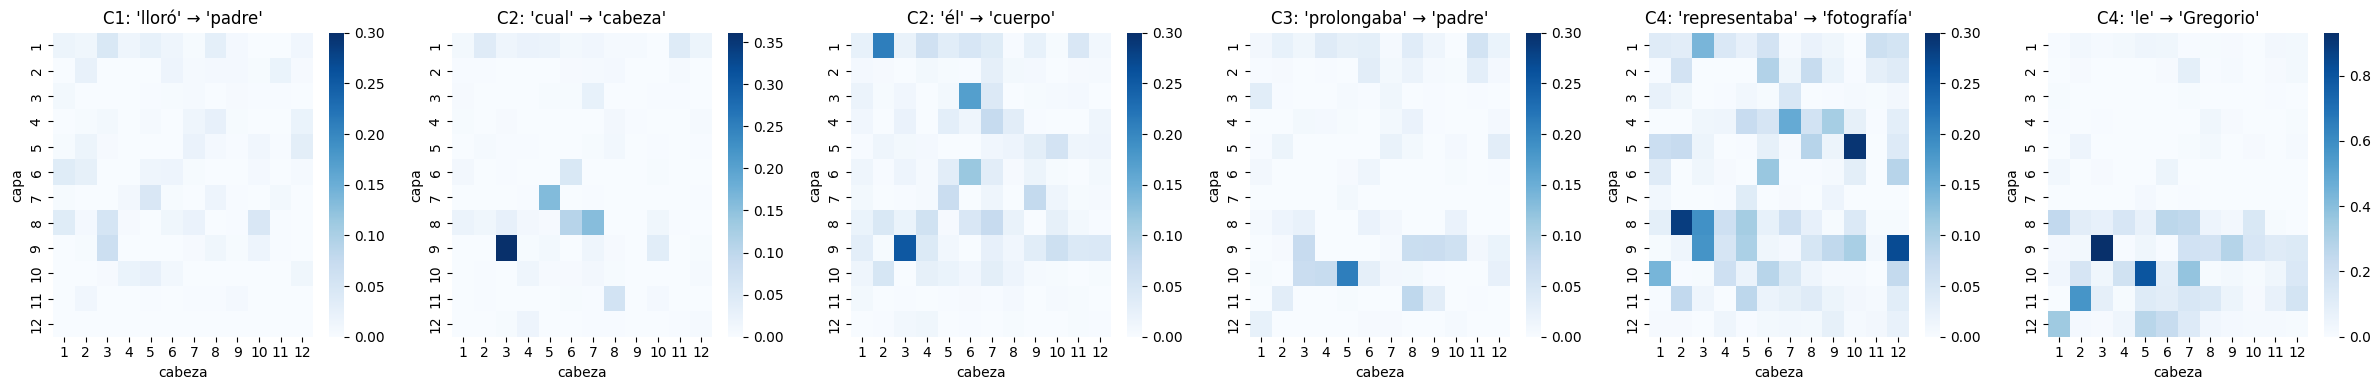

,oracion,desde,hacia,max_peso,capa_max,cabeza_max,peso_uniforme (1/n),rango_del_referente_en_esa_cabeza
0,C1,lloró,padre,0.067,9,3,0.013,4
1,C2,cual,cabeza,0.361,9,3,0.014,1
2,C2,él,cuerpo,0.254,9,3,0.014,2
3,C3,prolongaba,padre,0.211,10,5,0.020,2
4,C4,representaba,fotografía,0.293,5,10,0.029,1
5,C4,le,Gregorio,0.931,9,3,0.029,1


In [21]:
# ¿Alguna cabeza conecta la palabra con su referente/dependencia esperada?
referentes = [
    ("C1", "lloró", 0, "padre", 0),
    ("C2", "cual", 0, "cabeza", 0),
    ("C2", "él", 0, "cuerpo", 0),
    ("C3", "prolongaba", 0, "padre", 0),
    ("C4", "representaba", 0, "fotografía", 0),
    ("C4", "le", 0, "Gregorio", 0),
]
fig, axes = plt.subplots(1, len(referentes), figsize=(4 * len(referentes), 4))
filas = []
for ax, (k, w, ow, r, orr) in zip(axes, referentes):
    q = posiciones_palabra(k, w, ow)[0]
    rpos = posiciones_palabra(k, r, orr)
    M = datos[k]["att"][:, :, q, rpos].sum(-1)          # (12, 12)
    sns.heatmap(M, ax=ax, cmap="Blues", vmin=0, vmax=max(0.3, M.max()), cbar=True,
                xticklabels=range(1, 13), yticklabels=range(1, 13))
    ax.set_title(f"{k}: '{w}' → '{r}'"); ax.set_xlabel("cabeza"); ax.set_ylabel("capa")
    l, h = np.unravel_index(M.argmax(), M.shape)
    n = len(datos[k]["tokens"])
    filas.append({"oracion": k, "desde": w, "hacia": r, "max_peso": round(float(M.max()), 3),
                  "capa_max": l + 1, "cabeza_max": h + 1, "peso_uniforme (1/n)": round(1 / n, 3),
                  "rango_del_referente_en_esa_cabeza": int((datos[k]["att"][l, h, q] > M[l, h]).sum()) + 1})
plt.tight_layout(); plt.savefig(FIGURAS / "atencion_a_referentes.png", dpi=120); plt.show()
ref_df = pd.DataFrame(filas)
ref_df.to_csv(RESULTADOS / "atencion_a_referentes.csv", index=False, encoding="utf-8")
ref_df

La exploración sobre las 144 cabezas muestra que la cabeza con mayor atención a los referentes no está entre las seleccionadas a priori. Se reporta a continuación el top-5 (sin especiales) de esa cabeza para todas las palabras seleccionadas, como análisis complementario (selección *a posteriori*, por lo que debe leerse con cautela).

In [22]:
CAPA_REF, CABEZA_REF = map(int, ref_df.groupby(["capa_max", "cabeza_max"]).size().idxmax())
print(f"Cabeza más frecuente como máximo hacia el referente: capa {CAPA_REF}, cabeza {CABEZA_REF}")
filas = []
for k, o in oraciones.items():
    for palabra in o["palabras"]:
        ocurr = 1 if (k == "C3" and palabra == "desayuno") else 0
        q = posiciones_palabra(k, palabra, ocurr)[0]
        filas.append({"oracion": k, "palabra": palabra,
                      "top5_bruto": fmt(top_k(k, CAPA_REF, CABEZA_REF, q)),
                      "top5_sin_especiales": fmt(top_k(k, CAPA_REF, CABEZA_REF, q, excluir_especiales=True))})
cabeza_ref = pd.DataFrame(filas)
cabeza_ref.to_csv(RESULTADOS / f"top5_capa{CAPA_REF}_cabeza{CABEZA_REF}.csv", index=False, encoding="utf-8")
cabeza_ref

Cabeza más frecuente como máximo hacia el referente: capa 9, cabeza 3


,oracion,palabra,top5_bruto,top5_sin_especiales
0,C1,lloró,"[CLS]@0 (0.227) | ojos@49 (0.078) | Gregorio@25 (0.068) | padre@2 (0.067) | ,@43 (0.048)","ojos@49 (0.078) | Gregorio@25 (0.068) | padre@2 (0.067) | ,@43 (0.048) | ##ó@47 (0.047)"
1,C1,su,Gregorio@25 (0.507) | [CLS]@0 (0.253) | padre@2 (0.080) | El@1 (0.035) | [SEP]@76 (0.030),Gregorio@25 (0.507) | padre@2 (0.080) | El@1 (0.035) | a@24 (0.022) | habitación@28 (0.009)
2,C2,cual,"cabeza@50 (0.361) | la@49 (0.280) | ,@51 (0.076) | la@60 (0.043) | [CLS]@0 (0.042)","cabeza@50 (0.361) | la@49 (0.280) | ,@51 (0.076) | la@60 (0.043) | ,@58 (0.032)"
3,C2,él,su@44 (0.275) | cuerpo@45 (0.254) | Gregorio@1 (0.100) | mitad@42 (0.084) | de@43 (0.047),su@44 (0.275) | cuerpo@45 (0.254) | Gregorio@1 (0.100) | mitad@42 (0.084) | de@43 (0.047)
4,C3,prolongaba,"día@34 (0.353) | comida@31 (0.093) | del@33 (0.089) | padre@24 (0.075) | ,@35 (0.062)","día@34 (0.353) | comida@31 (0.093) | del@33 (0.089) | padre@24 (0.075) | ,@35 (0.062)"
5,C3,desayuno,[CLS]@0 (0.201) | [SEP]@49 (0.189) | ##yu@10 (0.065) | desa@9 (0.063) | ##yu@27 (0.049),##yu@10 (0.065) | desa@9 (0.063) | ##yu@27 (0.049) | ##no@11 (0.045) | ##no@28 (0.039)
6,C4,representaba,Gregorio@15 (0.311) | fotografía@13 (0.185) | de@14 (0.137) | una@12 (0.094) | que@25 (0.077),Gregorio@15 (0.311) | fotografía@13 (0.185) | de@14 (0.137) | una@12 (0.094) | que@25 (0.077)
7,C4,le,"Gregorio@15 (0.931) | de@14 (0.021) | ,@16 (0.019) | [SEP]@34 (0.009) | le@26 (0.009)","Gregorio@15 (0.931) | de@14 (0.021) | ,@16 (0.019) | .@33 (0.001) | fotografía@13 (0.001)"
8,S1,aclarado,día@4 (0.537) | el@3 (0.239) | había@5 (0.054) | ##do@8 (0.038) | ac@6 (0.031),día@4 (0.537) | el@3 (0.239) | había@5 (0.054) | ##do@8 (0.038) | Entre@1 (0.019)
9,S1,día,día@4 (0.183) | había@5 (0.154) | ##do@8 (0.129) | ac@6 (0.104) | el@3 (0.100),había@5 (0.154) | ##do@8 (0.129) | ac@6 (0.104) | el@3 (0.100) | .@9 (0.059)


## 6. Parte D — Comparación entre oraciones y contextos

### 6.1 Misma palabra, contexto distinto: *hoja* y *banco*

In [23]:
for a, b in [("H1", "H2"), ("B1", "B2")]:
    palabra = oraciones[a]["palabras"][0]
    filas = []
    for capa in CAPAS + [CAPA_REF]:
        pares = seleccion[capa].items() if capa in seleccion else [("referencial", CABEZA_REF)]
        for rol, cabeza in pares:
            fila = {"capa": capa, "cabeza": cabeza, "rol": rol}
            for k in (a, b):
                q = posiciones_palabra(k, palabra)[0]
                fila[f"{k}: {oraciones[k]['texto']}"] = fmt(top_k(k, capa, cabeza, q, excluir_especiales=True))
            filas.append(fila)
    comp = pd.DataFrame(filas)
    comp.to_csv(RESULTADOS / f"contraste_{palabra}.csv", index=False, encoding="utf-8")
    print(f"=== '{palabra}' (top-5 sin especiales) ===")
    display(comp)

=== 'hoja' (top-5 sin especiales) ===


,capa,cabeza,rol,H1: Gregorio se apoyó en la hoja de la puerta que permanecía cerrada.,H2: El viento arrancó una hoja seca del árbol del jardín.
0,3,8,posicional,la@6 (0.429) | en@5 (0.004) | ##ja@8 (0.004) | de@9 (0.002) | ##cía@15 (0.002),una@6 (0.402) | seca@9 (0.005) | ##ja@8 (0.005) | ##ó@5 (0.004) | ##nc@4 (0.001)
1,3,1,contextual,.@19 (0.056) | se@2 (0.016) | ##ja@8 (0.014) | que@12 (0.013) | de@9 (0.012),.@14 (0.069) | El@1 (0.025) | viento@2 (0.015) | una@6 (0.014) | ##ja@8 (0.013)
2,7,10,posicional,##ja@8 (0.999) | ##yó@4 (0.000) | puerta@11 (0.000) | de@9 (0.000) | la@10 (0.000),##ja@8 (0.999) | ##nc@4 (0.000) | seca@9 (0.000) | ##ó@5 (0.000) | árbol@11 (0.000)
3,7,7,contextual,.@19 (0.170) | puerta@11 (0.132) | que@12 (0.131) | ce@16 (0.071) | per@13 (0.064),.@14 (0.243) | árbol@11 (0.104) | del@10 (0.103) | seca@9 (0.068) | jardín@13 (0.062)
4,11,4,posicional,la@6 (0.909) | la@10 (0.046) | en@5 (0.013) | ce@16 (0.007) | .@19 (0.002),una@6 (0.502) | El@1 (0.041) | .@14 (0.030) | del@10 (0.020) | ##ó@5 (0.015)
5,11,8,contextual,puerta@11 (0.125) | apo@3 (0.086) | ce@16 (0.081) | la@6 (0.050) | en@5 (0.049),.@14 (0.061) | arra@3 (0.058) | ##ja@8 (0.050) | una@6 (0.044) | del@10 (0.036)
6,9,3,referencial,puerta@11 (0.176) | en@5 (0.080) | Gregorio@1 (0.080) | apo@3 (0.063) | ##ja@8 (0.061),árbol@11 (0.213) | del@10 (0.147) | ##ja@8 (0.106) | una@6 (0.089) | seca@9 (0.084)


=== 'banco' (top-5 sin especiales) ===


,capa,cabeza,rol,B1: El banco aprobó el préstamo.,B2: Me senté en el banco del parque.
0,3,8,posicional,El@1 (0.614) | ap@3 (0.007) | ##robó@4 (0.002) | ##mo@8 (0.001) | ##sta@7 (0.001),el@5 (0.407) | en@4 (0.009) | parque@8 (0.006) | del@7 (0.006) | Me@1 (0.001)
1,3,1,contextual,##robó@4 (0.137) | ##mo@8 (0.092) | .@9 (0.087) | El@1 (0.070) | el@5 (0.053),Me@1 (0.145) | .@9 (0.110) | parque@8 (0.078) | sent@2 (0.056) | del@7 (0.047)
2,7,10,posicional,ap@3 (0.106) | El@1 (0.088) | ##robó@4 (0.036) | pré@6 (0.003) | el@5 (0.002),del@7 (0.966) | parque@8 (0.007) | el@5 (0.002) | .@9 (0.001) | en@4 (0.001)
3,7,7,contextual,##robó@4 (0.197) | .@9 (0.157) | el@5 (0.106) | ap@3 (0.100) | El@1 (0.060),.@9 (0.348) | parque@8 (0.155) | del@7 (0.061) | Me@1 (0.023) | el@5 (0.022)
4,11,4,posicional,El@1 (0.797) | el@5 (0.057) | ap@3 (0.013) | .@9 (0.006) | ##robó@4 (0.006),el@5 (0.973) | del@7 (0.008) | en@4 (0.002) | parque@8 (0.001) | .@9 (0.000)
5,11,8,contextual,.@9 (0.155) | pré@6 (0.135) | El@1 (0.123) | el@5 (0.087) | ##sta@7 (0.078),el@5 (0.153) | .@9 (0.129) | parque@8 (0.127) | del@7 (0.113) | en@4 (0.080)
6,9,3,referencial,El@1 (0.226) | .@9 (0.061) | ##robó@4 (0.026) | pré@6 (0.022) | ap@3 (0.017),parque@8 (0.371) | el@5 (0.143) | del@7 (0.118) | en@4 (0.046) | .@9 (0.021)


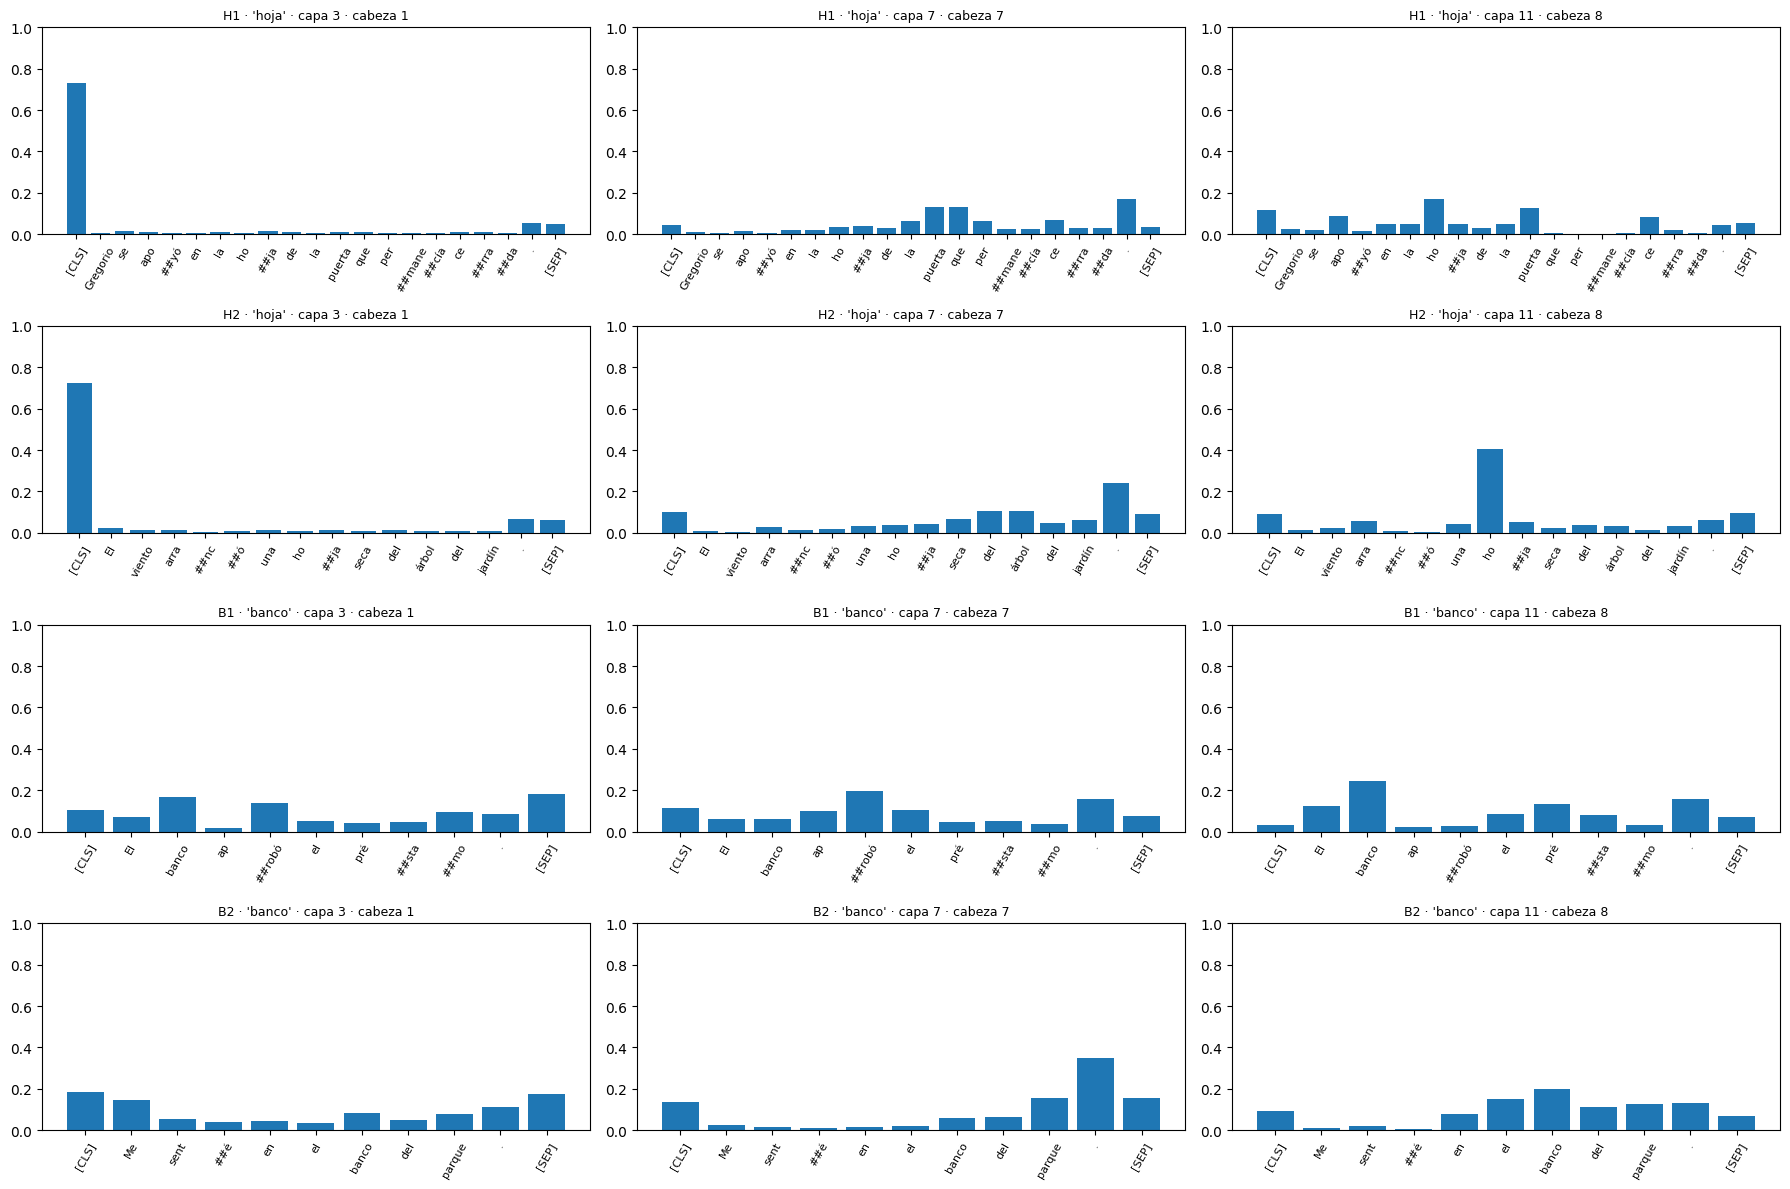

In [24]:
fig, axes = plt.subplots(4, 3, figsize=(18, 12))
for r, k in enumerate(["H1", "H2", "B1", "B2"]):
    palabra = oraciones[k]["palabras"][0]
    q = posiciones_palabra(k, palabra)[0]
    for c_i, capa in enumerate(CAPAS):
        ax = axes[r, c_i]
        h = seleccion[capa]["contextual"]
        ax.bar(range(len(datos[k]["tokens"])), datos[k]["att"][capa - 1, h - 1, q], color="tab:blue")
        ax.set_xticks(range(len(datos[k]["tokens"])))
        ax.set_xticklabels(datos[k]["tokens"], rotation=60, fontsize=8)
        ax.set_ylim(0, 1)
        ax.set_title(f"{k} · '{palabra}' · capa {capa} · cabeza {h}", fontsize=9)
plt.tight_layout(); plt.savefig(FIGURAS / "contraste_hoja_banco.png", dpi=120); plt.show()

La atención es una distribución **sobre los tokens de cada oración**, así que no se puede comparar directamente entre oraciones distintas (los tokens disponibles son otros). Como complemento se mide cuánto cambia la **representación** del token (*hidden state*) en cada capa: similitud coseno entre el vector de *hoja* (o *banco*) en un contexto y en el otro. Si el contexto modifica la representación, la similitud debe bajar a medida que se avanza en las capas.

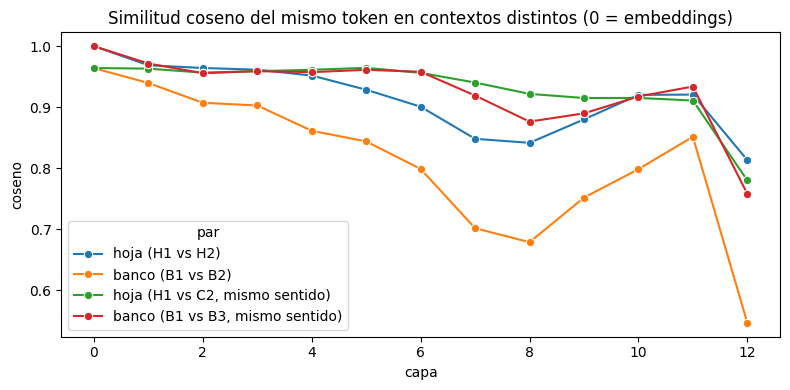

par,banco (B1 vs B2),"banco (B1 vs B3, mismo sentido)","hoja (H1 vs C2, mismo sentido)",hoja (H1 vs H2)
capa,,,,
0,0.964,1.000,0.964,1.000
1,0.940,0.972,0.963,0.969
2,0.907,0.956,0.957,0.964
3,0.903,0.959,0.959,0.961
4,0.861,0.957,0.961,0.952
5,0.844,0.961,0.965,0.929
6,0.799,0.958,0.956,0.901
7,0.702,0.919,0.940,0.848
8,0.679,0.876,0.922,0.842


In [25]:
def cos(u, v):
    return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))

filas = []
for a, b in [("H1", "H2"), ("B1", "B2")]:
    palabra = oraciones[a]["palabras"][0]
    qa, qb = posiciones_palabra(a, palabra)[0], posiciones_palabra(b, palabra)[0]
    for capa in range(13):
        filas.append({"par": f"{palabra} ({a} vs {b})", "capa": capa,
                      "coseno": cos(datos[a]["hid"][capa, qa], datos[b]["hid"][capa, qb])})
# Referencias: misma palabra en el mismo sentido
for a, b, palabra in [("H1", "C2", "hoja"), ("B1", "B3", "banco")]:
    qa = posiciones_palabra(a, palabra)[0]; qc = posiciones_palabra(b, palabra)[0]
    for capa in range(13):
        filas.append({"par": f"{palabra} ({a} vs {b}, mismo sentido)", "capa": capa,
                      "coseno": cos(datos[a]["hid"][capa, qa], datos[b]["hid"][capa, qc])})
sim = pd.DataFrame(filas)
sim.to_csv(RESULTADOS / "similitud_representaciones.csv", index=False, encoding="utf-8")
plt.figure(figsize=(8, 4))
sns.lineplot(data=sim, x="capa", y="coseno", hue="par", marker="o")
plt.title("Similitud coseno del mismo token en contextos distintos (0 = embeddings)")
plt.tight_layout(); plt.savefig(FIGURAS / "similitud_contexto.png", dpi=120); plt.show()
sim.pivot(index="capa", columns="par", values="coseno").round(3)

### 6.2 Oraciones simples vs. complejas

In [26]:
def estadisticas(k):
    A = datos[k]["att"]; n = A.shape[-1]
    q = np.arange(1, n - 1)
    dist = np.abs(np.arange(n)[None, :] - q[:, None])                    # |i - j|
    especiales = A[:, :, q][:, :, :, [0, n - 1]].sum(-1).mean()
    ent = (-(A[:, :, q] * np.log(A[:, :, q] + 1e-12)).sum(-1)).mean()
    ent_norm = ent / np.log(n)
    dist_media = (A[:, :, q] * dist[None, None]).sum(-1).mean()
    maxw = A[:, :, q].max(-1).mean()
    return {"oracion": k, "tipo": oraciones[k]["tipo"], "n_tokens": n,
            "masa_a_especiales": especiales, "entropía": ent, "entropía_norm": ent_norm,
            "distancia_media_atendida": dist_media, "distancia_media/n": dist_media / n,
            "peso_max_medio": maxw}

est = pd.DataFrame([estadisticas(k) for k in oraciones]).round(3)
est.to_csv(RESULTADOS / "simples_vs_complejas.csv", index=False, encoding="utf-8")
display(est)
display(est[est.tipo != "contraste"].groupby("tipo").mean(numeric_only=True).round(3))

,oracion,tipo,n_tokens,masa_a_especiales,entropía,entropía_norm,distancia_media_atendida,distancia_media/n,peso_max_medio
0,C1,compleja,77,0.411,1.984,0.457,22.427,0.291,0.501
1,C2,compleja,69,0.405,1.998,0.472,20.185,0.293,0.485
2,C3,compleja,50,0.259,2.170,0.555,12.313,0.246,0.408
3,C4,compleja,35,0.254,2.064,0.581,8.621,0.246,0.412
4,S1,simple,11,0.345,1.512,0.631,3.073,0.279,0.489
5,S2,simple,10,0.392,1.487,0.646,2.926,0.293,0.482
6,H1,contraste,21,0.280,1.832,0.602,5.602,0.267,0.441
7,H2,contraste,16,0.318,1.699,0.613,4.434,0.277,0.451
8,B1,contraste,11,0.365,1.546,0.645,3.192,0.290,0.471
9,B2,contraste,11,0.313,1.507,0.628,2.864,0.260,0.482


,n_tokens,masa_a_especiales,entropía,entropía_norm,distancia_media_atendida,distancia_media/n,peso_max_medio
tipo,,,,,,,
compleja,57.75,0.332,2.054,0.516,15.886,0.269,0.452
simple,10.50,0.368,1.500,0.639,3.000,0.286,0.485


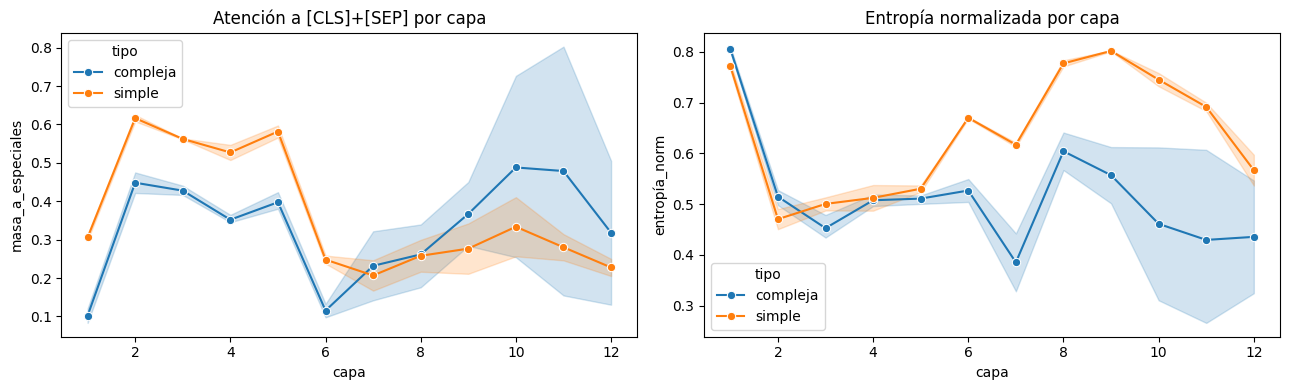

In [27]:
# Masa a especiales por capa: simples vs. complejas
filas = []
for k, o in oraciones.items():
    if o["tipo"] == "contraste":
        continue
    A = datos[k]["att"]; n = A.shape[-1]; q = np.arange(1, n - 1)
    for capa in range(12):
        filas.append({"oracion": k, "tipo": o["tipo"], "capa": capa + 1,
                      "masa_a_especiales": float(A[capa][:, q][:, :, [0, n - 1]].sum(-1).mean()),
                      "entropía_norm": float((-(A[capa][:, q] * np.log(A[capa][:, q] + 1e-12)).sum(-1)).mean() / np.log(n))})
por_capa = pd.DataFrame(filas)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=por_capa, x="capa", y="masa_a_especiales", hue="tipo", marker="o", ax=axes[0])
sns.lineplot(data=por_capa, x="capa", y="entropía_norm", hue="tipo", marker="o", ax=axes[1])
axes[0].set_title("Atención a [CLS]+[SEP] por capa"); axes[1].set_title("Entropía normalizada por capa")
plt.tight_layout(); plt.savefig(FIGURAS / "simples_vs_complejas_por_capa.png", dpi=120); plt.show()

### 6.3 Cambios entre capas y entre cabezas (cuantitativo)

In [28]:
# Para cada palabra seleccionada: solapamiento (Jaccard) del top-5 sin especiales entre capas (misma rol de cabeza)
# y entre las dos cabezas de una misma capa.
def conj(k, capa, cabeza, q):
    return {j for _, j, _ in top_k(k, capa, cabeza, q, excluir_especiales=True)}

def jac(a, b):
    return len(a & b) / len(a | b)

filas = []
for k, o in oraciones.items():
    for palabra in o["palabras"]:
        ocurr = 1 if (k == "C3" and palabra == "desayuno") else 0
        q = posiciones_palabra(k, palabra, ocurr)[0]
        S = {(c, r): conj(k, c, h, q) for c in CAPAS for r, h in seleccion[c].items()}
        filas.append({"oracion": k, "palabra": palabra,
                      "entre_cabezas_capa3": jac(S[(3, "posicional")], S[(3, "contextual")]),
                      "entre_cabezas_capa7": jac(S[(7, "posicional")], S[(7, "contextual")]),
                      "entre_cabezas_capa11": jac(S[(11, "posicional")], S[(11, "contextual")]),
                      "entre_capas_3_11_contextual": jac(S[(3, "contextual")], S[(11, "contextual")]),
                      "entre_capas_3_11_posicional": jac(S[(3, "posicional")], S[(11, "posicional")])})
jacc = pd.DataFrame(filas).round(2)
jacc.to_csv(RESULTADOS / "solapamiento_top5.csv", index=False, encoding="utf-8")
display(jacc)
jacc.mean(numeric_only=True).round(2)

,oracion,palabra,entre_cabezas_capa3,entre_cabezas_capa7,entre_cabezas_capa11,entre_capas_3_11_contextual,entre_capas_3_11_posicional
0,C1,lloró,0.00,0.43,0.00,0.11,0.25
1,C1,su,0.11,0.25,0.00,0.11,0.11
2,C2,cual,0.11,0.43,0.11,0.11,0.25
3,C2,él,0.00,0.25,0.11,0.25,0.25
4,C3,prolongaba,0.11,0.25,0.11,0.43,0.43
5,C3,desayuno,0.00,0.00,0.00,0.11,0.11
6,C4,representaba,0.25,0.43,0.11,0.11,0.43
7,C4,le,0.43,0.25,0.11,0.11,0.25
8,S1,aclarado,0.43,0.67,0.67,0.67,1.00
9,S1,día,0.25,0.43,0.67,0.67,0.43


entre_cabezas_capa3            0.34
entre_cabezas_capa7            0.38
entre_cabezas_capa11           0.37
entre_capas_3_11_contextual    0.35
entre_capas_3_11_posicional    0.40
dtype: float64

## 7. Subpalabras

Cuando una palabra se divide en varias piezas, el modelo tiene **varias filas y columnas** para la misma palabra. Se estudia: (a) cuánto se atienden las piezas entre sí, y (b) cómo cambia el top-5 al agregar la atención a nivel de palabra (promedio sobre las piezas de origen y suma sobre las piezas de destino, como en Clark et al., 2019).

In [29]:
casos_sub = subpalabras[subpalabras.oracion.isin(["C1", "C2", "C3", "C4", "S1", "S2"])].copy()
filas = []
for _, r in casos_sub.iterrows():
    k = r.oracion
    pos = posiciones_palabra(k, r.palabra)
    A = datos[k]["att"]
    intra = A[:, :, pos][:, :, :, pos].sum(-1).mean(-1)          # (12, 12): masa que las piezas dan a su propia palabra
    n = A.shape[-1]
    filas.append({"oracion": k, "palabra": r.palabra, "piezas": r.piezas,
                  "masa_intra_palabra (media capas/cabezas)": float(intra.mean()),
                  "esperado_si_uniforme": len(pos) / n,
                  "capa_con_mayor_masa_intra": int(intra.mean(1).argmax()) + 1})
intra_df = pd.DataFrame(filas).round(3).sort_values("masa_intra_palabra (media capas/cabezas)", ascending=False)
intra_df.to_csv(RESULTADOS / "subpalabras_masa_intra.csv", index=False, encoding="utf-8")
intra_df

,oracion,palabra,piezas,masa_intra_palabra (media capas/cabezas),esperado_si_uniforme,capa_con_mayor_masa_intra
27,S1,aclarado,ac ##lara ##do,0.295,0.273,12
25,C4,enfrente,en ##fre ##nte,0.275,0.086,12
22,C3,prolongaba,pro ##long ##aba,0.269,0.060,12
30,S2,lluvia,ll ##uvia,0.265,0.200,12
19,C3,vajilla,va ##jil ##la,0.264,0.060,12
28,S2,Todavía,Toda ##vía,0.257,0.200,12
29,S2,caía,ca ##ía,0.253,0.200,12
20,C3,desayuno,desa ##yu ##no,0.227,0.060,7
9,C1,robusto,ro ##bust ##o,0.201,0.039,12
6,C1,inseguro,ins ##egu ##ro,0.194,0.039,12


In [30]:
def atencion_palabras(k, capa, cabeza):
    # Matriz de atención palabra->palabra: media sobre piezas de origen, suma sobre piezas de destino.
    d = datos[k]; A = d["att"][capa - 1, cabeza - 1]
    grupos, etiquetas = [], []
    for i, (t, w) in enumerate(zip(d["tokens"], d["word_ids"])):
        if w is None:
            grupos.append([i]); etiquetas.append(t)
        elif i > 0 and d["word_ids"][i - 1] == w:
            grupos[-1].append(i)
        else:
            grupos.append([i]); etiquetas.append(d["palabras"][w])
    W = np.array([[A[np.ix_(g1, g2)].sum(1).mean() for g2 in grupos] for g1 in grupos])
    return pd.DataFrame(W, index=etiquetas, columns=etiquetas), grupos

# Ejemplo: palabras divididas en C1 — top-5 usando 1.ª pieza, última pieza y la palabra agregada
filas = []
ejemplos = casos_sub[casos_sub.oracion == "C1"].palabra.tolist()[:3]
for palabra in ejemplos:
    pos = posiciones_palabra("C1", palabra)
    for capa in CAPAS:
        h = seleccion[capa]["contextual"]
        W, grupos = atencion_palabras("C1", capa, h)
        widx = [i for i, g in enumerate(grupos) if g == pos][0]
        fila_w = W.iloc[widx].drop(index=[W.index[widx], "[CLS]", "[SEP]"], errors="ignore").sort_values(ascending=False)
        filas.append({"palabra": palabra, "piezas": " ".join(datos["C1"]["tokens"][p] for p in pos),
                      "capa": capa, "cabeza": h,
                      "top5_primera_pieza": fmt(top_k("C1", capa, h, pos[0], excluir_especiales=True)),
                      "top5_ultima_pieza": fmt(top_k("C1", capa, h, pos[-1], excluir_especiales=True)),
                      "top5_palabra_agregada": " | ".join(f"{t} ({v:.3f})" for t, v in fila_w.head(5).items())})
sub_top = pd.DataFrame(filas)
sub_top.to_csv(RESULTADOS / "subpalabras_top5.csv", index=False, encoding="utf-8")
sub_top

,palabra,piezas,capa,cabeza,top5_primera_pieza,top5_ultima_pieza,top5_palabra_agregada
0,cerró,ce ##rr ##ó,3,1,",@29 (0.045) | ,@13 (0.044) | ,@43 (0.025) | expresión@10 (0.023) | El@1 (0.019)","expresión@10 (0.049) | El@1 (0.039) | ,@29 (0.039) | ,@13 (0.029) | Gregorio@25 (0.025)",", (0.032) | expresión (0.030) | , (0.028) | quisiera (0.025) | El (0.023)"
1,cerró,ce ##rr ##ó,7,7,"con@9 (0.189) | expresión@10 (0.160) | ,@13 (0.145) | ##dora@12 (0.075) | como@14 (0.070)",",@13 (0.164) | con@9 (0.154) | expresión@10 (0.109) | como@14 (0.084) | ,@29 (0.070)","con (0.178) | , (0.150) | expresión (0.150) | amenazadora (0.113) | como (0.074)"
2,cerró,ce ##rr ##ó,11,8,.@75 (0.194) | tap@46 (0.062) | ##ó@56 (0.059) | amenaza@11 (0.048) | ll@54 (0.045),".@75 (0.112) | ##cía@70 (0.065) | ##ó@56 (0.050) | El@1 (0.038) | ,@13 (0.035)",. (0.129) | lloró (0.095) | estremecía (0.076) | tapó (0.060) | amenazadora (0.041)
3,puño,pu ##ño,3,1,",@29 (0.045) | ,@13 (0.038) | expresión@10 (0.032) | ,@43 (0.030) | El@1 (0.021)",",@29 (0.030) | padre@2 (0.027) | ,@13 (0.025) | Gregorio@25 (0.024) | expresión@10 (0.022)","cerró (0.039) | , (0.037) | , (0.031) | expresión (0.027) | , (0.025)"
4,puño,pu ##ño,7,7,",@13 (0.147) | expresión@10 (0.100) | amenaza@11 (0.062) | como@14 (0.060) | con@9 (0.056)",",@13 (0.255) | como@14 (0.104) | expresión@10 (0.091) | ##dora@12 (0.046) | ,@29 (0.043)",", (0.201) | expresión (0.095) | amenazadora (0.094) | como (0.082) | cerró (0.048)"
5,puño,pu ##ño,11,8,.@75 (0.073) | amenaza@11 (0.028) | padre@2 (0.026) | ll@73 (0.022) | Gregorio@25 (0.019),".@75 (0.072) | padre@2 (0.027) | pu@7 (0.022) | ll@54 (0.018) | ,@13 (0.018)",. (0.072) | lloró (0.036) | cerró (0.029) | padre (0.027) | estremecía (0.025)
6,amenazadora,amenaza ##dora,3,1,",@29 (0.036) | ,@13 (0.031) | ##ó@5 (0.029) | ,@43 (0.027) | expresión@10 (0.024)","expresión@10 (0.035) | Gregorio@25 (0.028) | ,@13 (0.027) | El@1 (0.025) | pu@7 (0.023)","cerró (0.049) | puño (0.034) | , (0.029) | expresión (0.029) | , (0.029)"
7,amenazadora,amenaza ##dora,7,7,",@13 (0.246) | como@14 (0.117) | ,@29 (0.067) | expresión@10 (0.061) | ##dora@12 (0.030)",",@13 (0.308) | ,@29 (0.145) | como@14 (0.111) | expresión@10 (0.053) | amenaza@11 (0.037)",", (0.277) | como (0.114) | , (0.106) | expresión (0.057) | con (0.024)"
8,amenazadora,amenaza ##dora,11,8,.@75 (0.098) | expresión@10 (0.043) | ##ó@5 (0.021) | ##cía@70 (0.021) | que@60 (0.018),".@75 (0.088) | expresión@10 (0.048) | ,@43 (0.038) | ,@13 (0.035) | amenaza@11 (0.025)",. (0.093) | expresión (0.046) | cerró (0.032) | estremecía (0.030) | llanto (0.027)


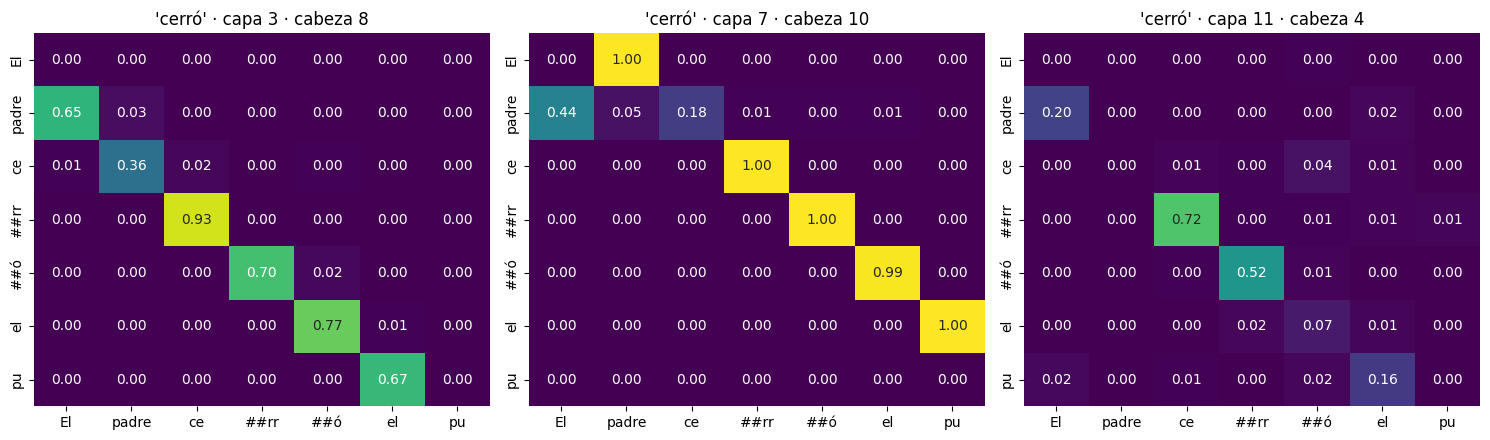

In [31]:
# Heatmap de una palabra fragmentada: atención entre sus piezas y las vecinas en todas las capas (cabeza posicional)
palabra = ejemplos[0]
pos = posiciones_palabra("C1", palabra)
lo, hi = max(1, pos[0] - 2), min(len(datos["C1"]["tokens"]) - 1, pos[-1] + 3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, capa in zip(axes, CAPAS):
    h = seleccion[capa]["posicional"]
    sub = datos["C1"]["att"][capa - 1, h - 1][lo:hi, lo:hi]
    toks = datos["C1"]["tokens"][lo:hi]
    sns.heatmap(sub, xticklabels=toks, yticklabels=toks, annot=True, fmt=".2f", cmap="viridis",
                vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(f"'{palabra}' · capa {capa} · cabeza {h}")
plt.tight_layout(); plt.savefig(FIGURAS / "subpalabras_heatmap.png", dpi=120); plt.show()

## 8. Preguntas de análisis

Las respuestas se apoyan en las tablas anteriores (también exportadas a `resultados/`). La notación `token@pos (peso)` es la misma de las tablas. Capas y cabezas se numeran de 1 a 12.

**Cabezas analizadas** (selección *a priori* por su perfil, sección 4): capa 3 → cabeza 8 (posicional, mira al token anterior) y cabeza 1 (contextual); capa 7 → cabeza 10 (posicional, mira al token siguiente) y cabeza 7 (contextual); capa 11 → cabeza 4 (posicional, token anterior) y cabeza 8 (contextual). Como complemento se incluye la capa 9, cabeza 3 (encontrada *a posteriori* por su atención a referentes).

### 1. ¿Qué tokens reciben mayor atención desde cada token seleccionado?

Depende sobre todo de **qué cabeza se mire**, más que de la palabra:

* **Tokens especiales y puntuación.** En las cabezas contextuales de capas 3 y 11 el primer lugar del top-5 bruto suele ser `[CLS]` (p. ej. *cual* → `[CLS]` 0.425 en capa 3; *él* → `[CLS]` 0.615 en capa 11), seguido de comas y el punto final. Entre las capas 2 y 5, en promedio, ~36–45 % de la atención va a `[CLS]`. Este comportamiento coincide con lo descrito por Clark et al. (2019): los tokens especiales y la puntuación funcionan como un “sumidero” o *no-op* cuando la cabeza no tiene nada específico que hacer.
* **Vecinos inmediatos.** Las cabezas posicionales dan casi toda su masa a un vecino: *día* → *el* (0.905, capa 3), *su* → *habitación* (1.000, capa 7), *cual* → *la* (0.922, capa 11). Dentro de palabras fragmentadas, la cabeza 7-10 conecta cada pieza con la siguiente (*ll* → `##or` 0.999, *pro* → `##long` 0.999).
* **Palabras de contenido del entorno sintáctico.** En la cabeza contextual de la capa 7 aparecen palabras relacionadas: *desayuno* → *comida* (0.163), *principal*, *era* (el predicado de “el desayuno era la comida principal”); *prolongaba* → *con*, *lectura*, *durante*, *periódicos* (sus complementos); *hoja* (H1) → *puerta* y *que*.
* **Referentes.** La cabeza 9-3 conecta pronombres con sus antecedentes: *le* → *Gregorio* (0.931), *cual* → *cabeza* (0.361, primer lugar), *él* → *su cuerpo* (0.275 + 0.254), *su* (C1) → *Gregorio* (0.507), *representaba* → *Gregorio* y *fotografía*.

### 2. ¿Cambian los patrones entre capas?

Sí, de forma sistemática (tabla de perfil por capa y figura `perfil_cabezas.png`):

* **Capa 1**: atención muy difusa (entropía normalizada 0.79) y poca masa en especiales (~14 % a `[CLS]`); se parece a una mezcla casi uniforme de la oración.
* **Capas 2–5**: dominan los sumideros (`[CLS]` recibe ~36–45 %) y algunas cabezas muy posicionales (3-8: 69 % al token anterior).
* **Capas 6–9**: baja la masa en `[CLS]` (~12–17 %) y aumentan los patrones de vecino (capa 7: 21 % al token siguiente) y las cabezas con relaciones sintácticas/correferenciales (9-3).
* **Capas 10–12**: vuelve a subir `[CLS]` en 10–11 y en la capa 12 crece mucho la atención a sí mismo (37 %), coherente con una última capa especializada en la tarea de preentrenamiento (predecir el propio token enmascarado).

Para una misma palabra, el top-5 cambia mucho entre capas: el solapamiento (Jaccard) del top-5 sin especiales entre capa 3 y capa 11 es en promedio 0.35 en las cabezas contextuales y 0.40 en las posicionales; en las oraciones complejas es aún menor (0.11 para *lloró*, *su*, *cual*, *representaba*). También cambia la **representación**: la similitud coseno de *banco* entre sus dos sentidos baja de 0.96 (embeddings) a 0.68 en la capa 8.

### 3. ¿Cambian los patrones entre cabezas?

Sí, y más que entre capas. Dentro de una misma capa conviven cabezas con funciones casi opuestas: en la capa 7 la cabeza 10 pone 93 % de su masa en el token siguiente (entropía 0.06), mientras la cabeza 7 reparte la atención sobre la oración (entropía 0.78). El Jaccard del top-5 entre las dos cabezas de una misma capa es en promedio 0.34–0.38, y en varias palabras de oraciones complejas es 0 (ningún token en común: *lloró* en capas 3 y 11, *él* en capa 3, *desayuno* en las tres capas). Esto respalda la idea de que la atención multi-cabeza reparte “subtareas” distintas, aunque muchas cabezas son redundantes o sólo atienden a `[CLS]`/`[SEP]`.

### 4. ¿Las palabras con mayor atención son lingüísticamente relevantes?

**A veces, pero no por defecto.**

* En el top-5 bruto, la mayoría de las posiciones altas las ocupan `[CLS]`, `[SEP]`, comas, el punto y artículos/preposiciones vecinas — tokens con poca relevancia semántica por sí mismos.
* Hay casos claramente relevantes: *le* → *Gregorio* (0.931), *cual* → *cabeza*, *él* → *cuerpo*, *desayuno* → *comida principal*, *prolongaba* → *lectura/periódicos*, *banco* (B2) → *parque* (0.371 en 9-3), *hoja* (H2) → *árbol*.
* Y hay fallos interesantes: *lloró* → *padre*, la dependencia sujeto–verbo a ~50 tokens en C1, nunca supera 0.067 en ninguna de las 144 cabezas (cuarto lugar en la mejor). *prolongaba* tiene como sujeto tácito al padre, pero la cabeza 9-3 mira sobre todo a *día* (0.353), el sustantivo más cercano — una heurística de proximidad, no necesariamente la relación correcta.

Que una cabeza conecte con el referente correcto en algunos ejemplos no significa que “resuelva correferencia” en general: la cabeza 9-3 fue elegida después de ver los resultados y se probó en pocas oraciones.

### 5. ¿Qué diferencias aparecen entre oraciones simples y complejas?

(Tabla `simples_vs_complejas` y figura por capa.)

* **Distancia de atención**: en las complejas la distancia media atendida es ~16 tokens frente a ~3 en las simples; normalizada por la longitud es similar (0.27 vs 0.29), es decir, la atención no se vuelve más “local” en términos relativos, pero sí alcanza tokens mucho más lejanos en términos absolutos.
* **Entropía**: la entropía absoluta es mayor en las complejas (2.05 vs 1.50 nats) porque hay más tokens, pero la **normalizada** es menor (0.52 vs 0.64): en oraciones largas cada token se concentra en una fracción más pequeña de la oración.
* **Sumideros**: no hay un patrón limpio; C1 y C2 (las más largas, con muchas comas) mandan ~41 % a `[CLS]/[SEP]`, C3 y C4 ~25 %, y las simples ~35–39 %.
* **Dependencias largas**: en las simples el sujeto y el verbo están a 1–3 tokens y la atención los conecta fácilmente (*aclarado* → *había*, *día*); en las complejas las dependencias a larga distancia (*lloró* ← *padre*) se pierden entre comas y cláusulas intermedias. Además, en las oraciones cortas el top-5 cubre casi media oración, por lo que el solapamiento entre capas/cabezas sale artificialmente alto (0.43–1.00 frente a 0.0–0.43 en las complejas).

**Cambio de contexto (Parte D).** Con *hoja* y *banco* la atención sí cambia con el contexto: *banco* atiende a *aprobó/préstamo* en B1 y a *parque/del* en B2; *hoja* atiende a *puerta* en H1 y a *árbol/seca* en H2. Pero esto es en parte trivial: cada oración tiene tokens distintos disponibles. La evidencia más fuerte de cambio contextual está en las representaciones: en la capa 8, *banco* en el mismo sentido (B1 vs B3) tiene similitud 0.88 y en sentidos distintos (B1 vs B2) 0.68; *hoja* en el mismo sentido (H1 vs C2) 0.92 y en sentidos distintos (H1 vs H2) 0.84. En la capa 12 todas las similitudes caen y la separación entre sentidos se reduce o incluso se invierte en *hoja*, otra señal de que la última capa está muy especializada.

### 6. ¿Qué ocurre cuando una palabra se divide en subpalabras?

* El tokenizer divide palabras frecuentes del español de forma no morfológica: *hoja* → `ho ##ja`, *lloró* → `ll ##or ##ó`, *desayuno* → `desa ##yu ##no`, *préstamo* → `pré ##sta ##mo`. Sólo a veces coincide con morfemas (*representa ##ba*, *mira ##ba*, *extend ##ían*).
* Las piezas de una misma palabra se atienden entre sí bastante más de lo esperado: p. ej. *prolongaba* da 27 % de su atención a sus propias piezas cuando bajo uniformidad sería 6 %; *enfrente* 28 % vs 9 %. Esto es máximo en la capa 12 para casi todas, y en la capa 7 la cabeza 10 enlaza cada pieza con la siguiente con peso ≈ 1. El modelo “recompone” la palabra internamente.
* El resultado del análisis depende de **qué pieza** se use como query: en C1 el top-5 desde la primera pieza de *cerró* (`ce`) y desde la última (`##ó`) comparten tokens, pero el orden y los pesos cambian, y al agregar a nivel de palabra aparecen palabras completas (*lloró*, *estremecía*, *tapó*) que antes estaban repartidas en varias columnas con poco peso cada una. Con subpalabras la atención que “recibe” una palabra se diluye entre sus piezas, así que una palabra fragmentada puede quedar fuera del top-5 aunque en conjunto reciba mucha atención. Para palabras divididas conviene agregar (suma sobre destino, promedio sobre origen).
* Los verbos en pasado (*cerró*, *miró*, *tapó*, *lloró*) comparten la pieza `##ó`; en la capa 11 cabeza 8 algunas piezas `##ó` se atienden entre sí (*cerró* → `##ó` de *lloró*), lo que sugiere que el modelo agrupa información de tiempo/persona a través de esa pieza.

### 7. ¿Qué no puedes concluir observando únicamente los pesos de atención?

* **Causalidad / importancia.** Un peso alto no implica que ese token sea el que determina la salida. Jain & Wallace (2019) muestran que se pueden obtener distribuciones de atención muy distintas con la misma predicción; Wiegreffe & Pinter (2019) matizan que la atención puede ser *una* explicación plausible pero no necesariamente *la* explicación. Para afirmar importancia se necesitan intervenciones (enmascarar tokens, *ablation* de cabezas, gradientes, *attention rollout/flow*).
* **El flujo real de información.** La atención mezcla *vectores value* que ya contienen información de otras posiciones de capas anteriores; además están las conexiones residuales, la normalización y las FFN. Lo que entra en `[CLS]` en la capa 3 no es la palabra “[CLS]”: puede ser información de toda la oración. Kobayashi et al. (2020) muestran que la masa enorme hacia `[CLS]`/`[SEP]` desaparece al considerar la norma de los vectores ponderados (‖α·f(x)‖).
* **Conocimiento sintáctico o semántico general.** Que la cabeza 9-3 una *le* con *Gregorio* en esta oración no prueba que el modelo resuelva correferencia; con pocos ejemplos y una selección *a posteriori* (se escogió la cabeza después de ver el resultado) el riesgo de sesgo de confirmación es alto. Habría que evaluar sobre un conjunto anotado.
* **El significado de una palabra.** Que *banco* mire a *parque* no dice por sí solo que el modelo “entendió” el sentido de asiento; esa conclusión requiere otra evidencia (como las similitudes de representaciones de la sección 6, o una tarea de desambiguación).
* **Comparaciones directas entre oraciones.** Los pesos son distribuciones sobre tokens distintos en cada oración y dependen de su longitud (1/n), así que un 0.2 en una oración de 10 tokens no equivale a un 0.2 en una de 77.
* **Unidades lingüísticas.** Las matrices están a nivel de subpalabra; cualquier conclusión sobre palabras depende de cómo se agreguen las piezas.

### Conclusión

Las matrices de atención de mBERT muestran patrones claros y reproducibles —sumideros en `[CLS]`/`[SEP]` y puntuación, cabezas posicionales, recomposición de subpalabras y algunas cabezas que conectan pronombres con antecedentes—, y esos patrones cambian con la capa, con la cabeza y con el contexto. Sin embargo, la atención es sólo uno de los componentes del cálculo del Transformer: sirve para formular hipótesis sobre qué relaciones podría estar modelando la red, no para confirmarlas. Las relaciones de larga distancia típicas de la prosa de Kafka (sujetos que gobiernan verbos a decenas de palabras) son justamente las que menos se reflejan en los pesos de atención directos.

### Referencias

* Clark, K., Khandelwal, U., Levy, O., & Manning, C. D. (2019). *What Does BERT Look At? An Analysis of BERT's Attention*. BlackboxNLP.
* Jain, S., & Wallace, B. C. (2019). *Attention is not Explanation*. NAACL.
* Wiegreffe, S., & Pinter, Y. (2019). *Attention is not not Explanation*. EMNLP.
* Kobayashi, G., Kuribayashi, T., Yokoi, S., & Inui, K. (2020). *Attention is Not Only a Weight: Analyzing Transformers with Vector Norms*. EMNLP.
* Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*. NAACL.